# Лабораторная работа №4
## Глубокое обучение и трансформерные архитектуры в анализе текстов

**Цель работы:** применить распределённые представления слов, рекуррентные нейросети и предобученный трансформер для анализа отзывов, а затем сравнить качество и вычислительную стоимость подходов.

Продолжаем работу с **Amazon Product Reviews**. Используем текст `reviews.text` и оценку `reviews.rating`. Классифицируем отзывы на **negative (1–2 звезды), neutral (3) и positive (4–5)**. Метки получены из рейтинга.

#### Импорты и воспроизводимость

Сначала подключаем библиотеки для обработки таблиц, подготовки эмбеддингов и визуализаций. Зафиксируем `SEED = 42`, создадим каталоги для файлов и зададим соответствие названий классов числовым индексам: 0, 1 и 2.

In [1]:
import json
import logging
import os
import random
import time
from pathlib import Path

os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
import torch
from gensim.models import Word2Vec
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    f1_score, precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import normalize
from sklearn.svm import LinearSVC
from spacy.lang.en.stop_words import STOP_WORDS
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

try:
    import kagglehub
except ModuleNotFoundError as exc:
    if exc.name != "kagglehub":
        raise
    kagglehub = None

try:
    import transformers
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
except ImportError as e:
    raise RuntimeError('Установите transformers в текущем ядре: %pip install "transformers>=4.44,<5" safetensors') from e

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")

In [3]:
RESULTS_DIR = Path("results")
for path in (DATA_DIR, MODEL_DIR, FIG_DIR, RESULTS_DIR):
    path.mkdir(parents=True, exist_ok=True)

LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {"negative": 0, "neutral": 1, "positive": 2}

### Подготовка датасета и разделение выборки

Используем тот же CSV, что и в прошлых работах. В отличие от синтаксического анализа здесь нам нужны **тексты и метки классов**, поэтому удалим строки без рейтинга, невалидные оценки, конфликтующие записи и точные дубликаты.

Для дальнейшего сравнения важно один раз зафиксировать три подвыборки: **Train** для обучения, **Validation** для выбора гиперпараметров и лучшей эпохи, **Test** для итоговых метрик. Ни один классификатор не должен настраиваться по тестовым ответам.

Основная метрика — **Macro F1**, поскольку около 84% отзывов положительные. Для каждого класса сначала рассчитывается F1, а затем три значения усредняются с одинаковым весом: $F1_{macro}=\frac{F1_{neg}+F1_{neu}+F1_{pos}}{3}$.

#### Загрузим исходный CSV

Проверяем несколько ожидаемых путей: рабочую папку, каталог `data` и кэш KaggleHub. Если локального файла нет, загружаем исходный датасет. Затем осматриваем размер таблицы и первые примеры текстов с оценками — это проверка входных данных до преобразований.

In [4]:
local_candidates = [
    DATA_DIR / "7817_1.csv",
    Path("7817_1.csv"),
    Path.home() / ".cache" / "kagglehub" / "datasets" / "yasserh" / "amazon-product-reviews-dataset" / "versions" / "1" / "7817_1.csv",
]
csv_path = next((p for p in local_candidates if p.exists()), None)
if csv_path is None:
    if kagglehub is None:
        raise RuntimeError("Для загрузки отсутствующего CSV установите kagglehub.")
    dataset_dir = Path(kagglehub.dataset_download("yasserh/amazon-product-reviews-dataset"))
    csv_path = dataset_dir / "7817_1.csv"

In [5]:
if not csv_path.exists():
    raise FileNotFoundError(f"Не найден CSV: {csv_path}")
raw = pd.read_csv(csv_path)
assert {"reviews.text", "reviews.rating"}.issubset(raw.columns), "Нужные колонки отсутствуют"
print("Источник:", csv_path)
print("Размер исходного файла:", raw.shape)
display(raw[["reviews.text", "reviews.rating"]].head(3))

Источник: C:\Users\sonyb\.cache\kagglehub\datasets\yasserh\amazon-product-reviews-dataset\versions\1\7817_1.csv
Размер исходного файла: (1597, 27)


,reviews.text,reviews.rating
0,I initially had trouble deciding between the p...,5.0
1,Allow me to preface this with a little history...,5.0
2,I am enjoying it so far. Great for reading. Ha...,4.0


#### Очистим отзывы и создадим метки

Для обучения оставляем только текст и рейтинг. Исключаем пропуски, пустые строки и значения рейтинга вне диапазона 1–5. Если один и тот же полный текст встречается с разными рейтингами, исключаем все его варианты (выбирать одну оценку произвольно некорректно).

In [6]:
df = raw[["reviews.text", "reviews.rating"]].rename(
    columns={"reviews.text": "Text", "reviews.rating": "Score"}
).copy()
df["source_row"] = raw.index

df = df.dropna(subset=["Text", "Score"]).copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["Score"] = pd.to_numeric(df["Score"], errors="coerce")
df = df[df["Score"].isin([1, 2, 3, 4, 5]) & df["Text"].ne("")].copy()
df["Score"] = df["Score"].astype(int)

conflict_count = df.groupby("Text")["Score"].nunique()

In [7]:
conflicting_texts = conflict_count[conflict_count > 1].index
df = df[~df["Text"].isin(conflicting_texts)]
df = df.drop_duplicates(subset="Text").reset_index(drop=True)

df["Sentiment"] = pd.cut(
    df["Score"], bins=[0, 2, 3, 5], labels=LABELS
).astype(str)
df["target"] = df["Sentiment"].map(LABEL_TO_ID).astype(int)

print("Итоговый объём:", len(df), "отзывов")
print(df["Sentiment"].value_counts().reindex(LABELS).to_string())
assert len(df) == 907, "Объём отличается от лабораторной №2: проверьте CSV и правила очистки"

Итоговый объём: 907 отзывов
Sentiment
negative     72
neutral      70
positive    765


In [8]:
assert df["Sentiment"].value_counts().to_dict() == {
    "positive": 765, "negative": 72, "neutral": 70
}, "Распределение отличается от лабораторной №2"
display(df[["Text", "Score", "Sentiment", "target"]].head(3))

,Text,Score,Sentiment,target
0,I initially had trouble deciding between the p...,5,positive,2
1,Allow me to preface this with a little history...,5,positive,2
2,I am enjoying it so far. Great for reading. Ha...,4,positive,2


#### Что получилось после очистки

Из **1597** исходных строк после исключения пропусков осталось **1177**, после устранения четырёх конфликтующих строк `Read more` — **1173**, а после удаления полных повторов — **907 уникальных отзывов**. Из них **72 negative, 70 neutral и 765 positive**.

Как и в предыдущих работах, значение `Sentiment` — это **группа по рейтингу**, а не вручную подтверждённая эмоциональная метка. В положительном отзыве могут обсуждаться недостатки, а в нейтральном — одновременно сильные и слабые стороны товара.

#### Зафиксируем Train, Validation и Test

Стратифицированное разделение сохраняет примерно одинаковые доли классов во всех трёх частях. Сначала откладываем 20% под Test, затем выделяем Validation из оставшегося Train+Validation. Сохраняем таблицы в CSV для последующих экспериментов.

In [9]:
trainval_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20,
    random_state=SEED, stratify=df["target"]
)

train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.20,
    random_state=SEED, stratify=df.iloc[trainval_idx]["target"]
)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
val_df = df.iloc[val_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

In [10]:
for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    frame.to_csv(DATA_DIR / f"lab4_{name}.csv", index=False, encoding="utf-8-sig")

split_stats = pd.DataFrame({
    name: x["Sentiment"].value_counts().reindex(LABELS, fill_value=0)
    for name, x in [("train", train_df), ("val", val_df), ("test", test_df)]
})

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
display(split_stats)
assert len(train_df) == 580 and len(val_df) == 145 and len(test_df) == 182

Train / Val / Test: 580 145 182


,train,val,test
Sentiment,,,
negative,46,12,14
neutral,45,11,14
positive,489,122,154


#### Проверка распределения

После стратификации получили **580 Train, 145 Validation и 182 Test**. На тесте — **14 негативных, 14 нейтральных и 154 позитивных** отзыва. При таком количестве редких классов одна-две ошибки способны заметно повлиять на Macro F1, поэтому итоговые оценки нельзя считать абсолютно устойчивыми.

### Шаг 1. Дистрибутивная семантика: собственная Word2Vec

**Идея Word2Vec:** слова, которые часто встречаются в похожих контекстах, получают близкие плотные векторные представления. В отличие от one-hot или Bag of Words, отдельное слово здесь задаётся не номером столбца, а координатами в векторном пространстве.

Выберем **Skip-gram**: модель по центральному слову предсказывает его контекст. Используем окно из пяти слов, вектора размерности 100 и 40 эпох обучения. Чтобы оценка классификаторов оставалась корректной, Word2Vec обучаем **только на Train**.

После обучения найдём пять ближайших слов для пяти тематических слов по косинусной близости и визуализируем не менее 100 слов с помощью t-SNE. Дополнительная группировка KMeans будет проводиться **до проекции**, на исходных нормированных векторах.

#### Лемматизация перед обучением эмбеддингов

Используем `en_core_web_sm`: лемматизация приводит формы вроде `reading` и `reads` к общей основе `read`. Числа и пунктуацию исключаем, но отрицание `not` оставляем: оно несёт важный смысл для тональности. Для Word2Vec формируем предложения из лемм, а для документов запоминаем последовательности токенов.

In [11]:
try:
    nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
except OSError as e:
    raise RuntimeError(
        "Не установлена en_core_web_sm. Выполните: python -m spacy download en_core_web_sm"
    ) from e
if "sentencizer" not in nlp.pipe_names:
    nlp.add_pipe("sentencizer")

In [12]:
def lemma_token(token):
    if token.lower_ in {"n't", "n’t"}:
        return "not"
    word = token.lemma_.lower().strip()
    if not word or not word.isalpha() or len(word) < 2:
        return None
    return word

train_sentences = []
train_tokens = []

In [13]:
for doc in nlp.pipe(train_df["Text"].tolist(), batch_size=32):
    doc_tokens = []
    for sent in doc.sents:
        sentence_tokens = [w for token in sent if (w := lemma_token(token)) is not None]
        if len(sentence_tokens) >= 2:
            train_sentences.append(sentence_tokens)
        doc_tokens.extend(sentence_tokens)
    train_tokens.append(doc_tokens)

print("Предложений для Word2Vec:", len(train_sentences))
print("Токенов в train:", sum(map(len, train_tokens)))
print("Пример токенов:", train_tokens[0][:30])
assert len(train_sentences) > 100, "Слишком мало предложений для обучения Word2Vec"

Предложений для Word2Vec: 3687
Токенов в train: 61189
Пример токенов: ['trs', 'heureux', 'que', 'le', 'livre', 'soient', 'sur', 'icloud', 'aprs', 'fait', 'voler', 'bien', 'de', 'pouvoir', 'retrouver', 'tous', 'me', 'livre', 'avec', 'toute', 'les', 'note', 'que', 'prise']


#### Обучение модели Skip-gram

Размерность векторов — 100, контекстное окно — 5, минимальная частота слова — 2. `negative=10` задаёт число отрицательных примеров в negative sampling. `workers=1` уменьшает недетерминированность обучения. Засекаем время и сохраняем модель для дальнейших шагов.

In [14]:
start = time.perf_counter()
w2v = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    negative=10,
    epochs=40,
    workers=1,
    seed=SEED,
)
training_seconds = time.perf_counter() - start

In [15]:
model_path = MODEL_DIR / "amazon_word2vec.model"
w2v.save(str(model_path))

print(f"Время обучения Word2Vec: {training_seconds:.2f} с")
print("Размер словаря:", len(w2v.wv))
print("Размерность вектора:", w2v.vector_size)
print("Пример вектора:", w2v.wv[w2v.wv.index_to_key[0]][:8])
assert len(w2v.wv) >= 100, "В словаре менее 100 слов — визуализация не удовлетворит заданию"

Время обучения Word2Vec: 16.51 с
Размер словаря: 2031
Размерность вектора: 100
Пример вектора: [ 0.24609038 -0.08647671 -0.07136199 -0.24200892  0.21467799  0.06324355
  0.14826378  0.19318089]


#### Результат обучения Word2Vec

На Train сформировано **3 687 предложений** и **61 189 токенов**. Обученный словарь содержит **2 031 слово**. Вектор каждого слова имеет **100 признаков**, а измеренное время обучения составило **16,51 секунды**. Это собственные эмбеддинги из нашего корпуса.

#### Пять ключевых слов и их ближайшие соседи

Для слов `kindle`, `screen`, `battery`, `book`, `device` найдём по пять самых похожих слов. Word2Vec возвращает **cosine similarity**, поэтому косинусное расстояние рассчитываем как `1 - similarity`. Большое сходство указывает на близость контекстов, но не обязательно на синонимию.

In [16]:
candidate_keywords = [
    "kindle", "screen", "battery", "book", "device",
    "read", "tablet", "amazon", "paperwhite", "light", "price", "reader"
]
keywords = [word for word in candidate_keywords if word in w2v.wv][:5]
assert len(keywords) == 5, "Найдено меньше пяти тематических слов; проверьте корпус и токенизацию"

neighbor_rows = []

In [17]:
for word in keywords:
    for rank, (neighbor, similarity) in enumerate(w2v.wv.most_similar(word, topn=5), 1):
        neighbor_rows.append({
            "keyword": word,
            "rank": rank,
            "neighbor": neighbor,
            "cosine_similarity": round(float(similarity), 4),
            "cosine_distance": round(float(1 - similarity), 4),
        })

neighbors_df = pd.DataFrame(neighbor_rows)
display(neighbors_df)
neighbors_df.to_csv(RESULTS_DIR / "word2vec_neighbors.csv", index=False, encoding="utf-8-sig")
print("Пять выбранных слов:", ", ".join(keywords))

,keyword,rank,neighbor,cosine_similarity,cosine_distance
0,kindle,1,motorola,0.5988,0.4012
1,kindle,2,differ,0.5894,0.4106
2,kindle,3,hddisplay,0.5805,0.4195
3,kindle,4,razr,0.5795,0.4205
4,kindle,5,transformer,0.5790,0.4210
5,screen,1,recommended,0.5238,0.4762
6,screen,2,overwhelmed,0.5079,0.4921
7,screen,3,settle,0.4993,0.5007
8,screen,4,pros,0.4990,0.5010
9,screen,5,density,0.4899,0.5101


Пять выбранных слов: kindle, screen, battery, book, device


#### Интерпретация ближайших слов

В сохранённом запуске для `battery` среди соседей оказались `life` (сходство **0,7160**) и `drain` (**0,5912**) — это правдоподобные совместные контексты аккумулятора. Но встречаются и неожиданные связи, например `kindle → motorola`. На небольшом специализированном корпусе Word2Vec может сближать слова по повторяющимся ситуациям употребления, не устанавливая точных смысловых отношений.

#### Подготовим слова для двумерной проекции

Возьмём 200 частотных содержательных слов, исключив стоп-слова. Затем нормируем их векторы, выделяем пять кластеров алгоритмом KMeans и только после этого применяем t-SNE для отображения на плоскости. Кластеры вычисляются в исходном 100-мерном пространстве, а не на плоскости t-SNE.

In [18]:
N_WORDS = 200
content_vocab = [
    word for word in w2v.wv.index_to_key
    if len(word) >= 3 and word not in STOP_WORDS and word.isalpha()
]
plot_words = content_vocab[:N_WORDS]
for word in keywords:
    if word not in plot_words:
        plot_words.append(word)
assert len(plot_words) >= 100, "В наборе визуализации менее 100 слов"

vectors = np.vstack([w2v.wv[word] for word in plot_words])

In [19]:
vectors_norm = normalize(vectors)

N_CLUSTERS = 5
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(vectors_norm)

In [20]:
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(plot_words) - 1) / 3),
    metric="euclidean",  # для нормированных векторов расстояние связано с cosine distance
    init="pca",
    learning_rate="auto",
    random_state=SEED,
    max_iter=1500,
)
coords = tsne.fit_transform(vectors_norm)

In [21]:
plot_df = pd.DataFrame({
    "word": plot_words,
    "tsne_x": coords[:, 0],
    "tsne_y": coords[:, 1],
    "cluster": cluster_labels,
    "frequency": [w2v.wv.get_vecattr(w, "count") for w in plot_words]
})
plot_df.to_csv(RESULTS_DIR / "word2vec_tsne.csv", index=False, encoding="utf-8-sig")
print("Число визуализированных слов:", len(plot_words))
print("Размеры кластеров:")
print(plot_df["cluster"].value_counts().sort_index().to_string())

Число визуализированных слов: 200
Размеры кластеров:
cluster
0    32
1    33
2    47
3    48
4    40


#### Визуализация смысловых групп

Для каждого кластера находим слова, ближайшие к его центроиду. На графике подпишем ключевые слова и несколько репрезентативных представителей. Так визуализацию можно интерпретировать без сотен пересекающихся подписей.

In [22]:
centroids = normalize(kmeans.cluster_centers_)
representative_words = {}
for cluster in range(N_CLUSTERS):
    positions = np.flatnonzero(cluster_labels == cluster)
    sims = vectors_norm[positions] @ centroids[cluster]
    top_positions = positions[np.argsort(-sims)[:10]]
    representative_words[cluster] = [plot_words[p] for p in top_positions]

In [23]:
summary_df = pd.DataFrame([
    {"cluster": i, "n_words": int(sum(cluster_labels == i)),
     "representative_words": ", ".join(representative_words[i])}
    for i in range(N_CLUSTERS)
])
display(summary_df)
summary_df.to_csv(RESULTS_DIR / "word2vec_clusters.csv", index=False, encoding="utf-8-sig")

,cluster,n_words,representative_words
0,0,32,"week, plug, charger, charge, nexus, purchase, ..."
1,1,33,"netflix, prime, app, store, interface, search,..."
2,2,47,"command, bluetooth, question, alexa, speaker, ..."
3,3,48,"portability, size, awesome, hand, overall, thi..."
4,4,40,"model, generation, fire, kindle, experience, y..."


In [24]:
def show_word2vec_tsne():
    fig, ax = plt.subplots(figsize=(13, 9))
    colors = plt.get_cmap("tab10")
    for cluster in range(N_CLUSTERS):
        subset = plot_df[plot_df["cluster"] == cluster]
        ax.scatter(subset["tsne_x"], subset["tsne_y"], s=48, alpha=0.75,
                   color=colors(cluster), label=f"Кластер {cluster + 1} ({len(subset)} слов)")

    words_to_label = set(keywords)
    for cluster in range(N_CLUSTERS):
        words_to_label.update(representative_words[cluster][:5])
    for row in plot_df.itertuples(index=False):
        if row.word in words_to_label:
            ax.annotate(row.word, (row.tsne_x, row.tsne_y),
                        xytext=(4, 4), textcoords="offset points", fontsize=9)

    ax.set_title(f"Word2Vec + t-SNE: {len(plot_words)} слов Amazon Product Reviews", fontsize=16)
    ax.set_xlabel("t-SNE 1 (условная координата)")
    ax.set_ylabel("t-SNE 2 (условная координата)")
    ax.legend(loc="best", fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "word2vec_tsne.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("График:", FIG_DIR / "word2vec_tsne.png")

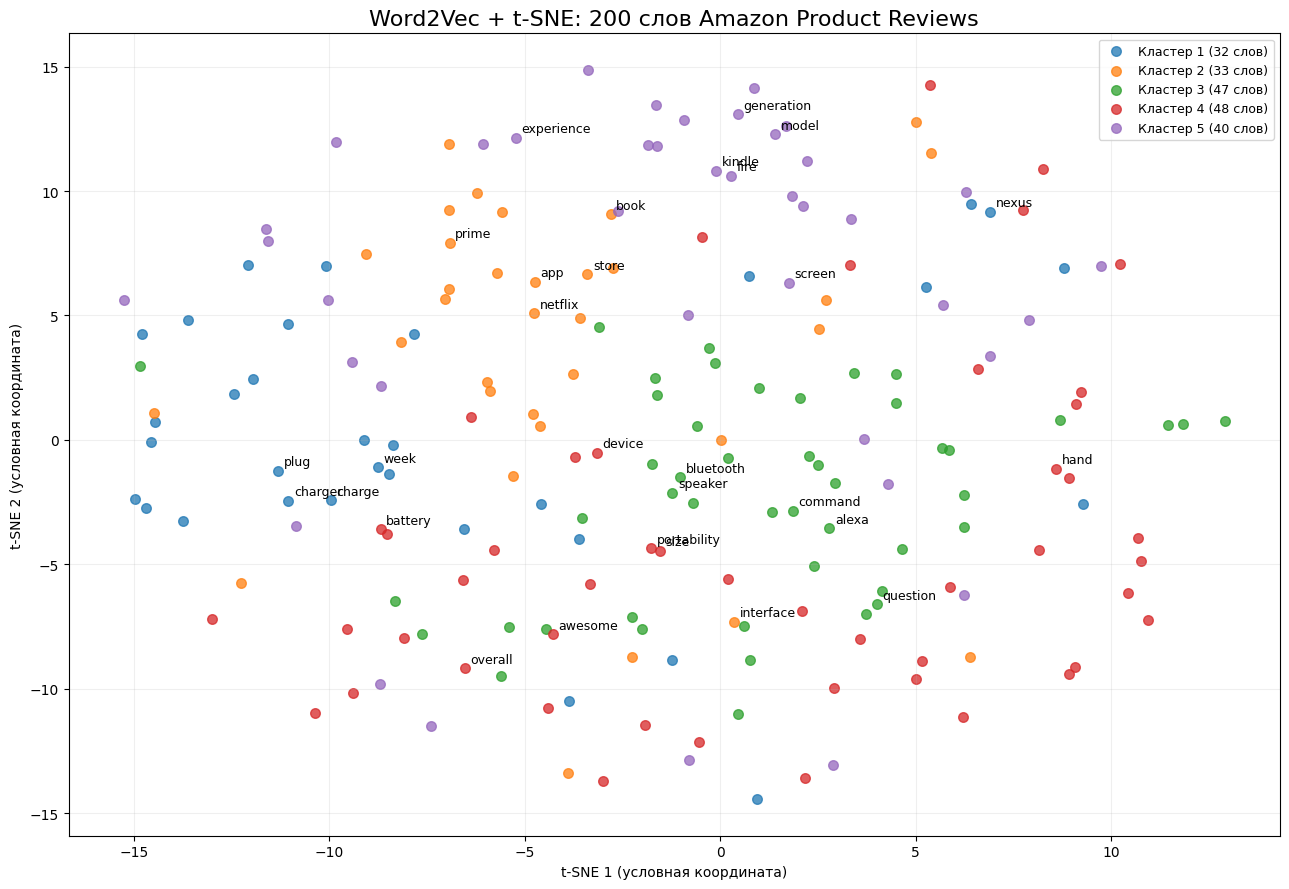

График: figures\word2vec_tsne.png


In [25]:
show_word2vec_tsne()

#### Вывод по Word2Vec и t-SNE

На графике показано **200 слов** и **5 кластеров**. В некоторых группах рядом оказываются термины об аккумуляторе и зарядке, приложениях, голосовом управлении, устройствах Kindle. Это согласуется с тематикой набора отзывов.

Однако t-SNE **искажает глобальные расстояния** и чувствителен к параметрам проекции. Цвета назначены KMeans по исходным эмбеддингам. Поэтому график служит способом наглядного изучения близостей, а не подтверждением строгой семантической классификации слов.

### Шаг 2. Промежуточный Baseline: Mean Pooling + Logistic Regression

Мы уже получили вектор для каждого **слова**, но классификатору нужен один фиксированный вектор для **всего отзыва**. Простой способ — усреднить Word2Vec-векторы известных слов:

$$\mathbf{d}=\frac{1}{|T_d|}\sum_{w\in T_d}\mathbf{v}(w),$$

где $T_d$ — слова документа, которые есть в словаре обученного Word2Vec. Если все слова оказались вне словаря, используем нулевой вектор и учитываем такой случай при анализе покрытия.

По полученным 100-мерным векторам обучим **Logistic Regression** с компенсацией дисбаланса. Параметр регуляризации `C` подбираем только по Validation Macro F1, а итоговые показатели показываем на Test.

#### Библиотеки для классификации и метрик

Подключим логистическую регрессию, метрики и DummyClassifier. Поскольку задача трёхклассовая и сильно несбалансированная, будем выводить не только Accuracy, но и отдельный `classification_report` и матрицу ошибок.

In [26]:
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
print("Размерность Word2Vec:", w2v.vector_size)

Train / Val / Test: 580 145 182
Размерность Word2Vec: 100


#### Превратим каждый отзыв в один вектор

В Word2Vec может не быть редких токенов из Validation и Test. Поэтому при усреднении берём только известные слова, а число пропущенных токенов учитываем отдельно. Функция возвращает и векторы, и статистику покрытия словаря для каждой части данных.

In [27]:
def tokenize_reviews(texts):
    return [
        [lemma for token in doc if (lemma := lemma_token(token)) is not None]
        for doc in nlp.pipe(texts, batch_size=32)
    ]

In [28]:
def mean_pool_word2vec(tokenized_reviews, model):
    X = np.zeros((len(tokenized_reviews), model.vector_size), dtype=np.float32)
    total_tokens = 0
    known_tokens = 0
    empty_vectors = 0

    for row_id, tokens in enumerate(tokenized_reviews):
        total_tokens += len(tokens)
        in_vocab = [token for token in tokens if token in model.wv]
        known_tokens += len(in_vocab)
        if in_vocab:
            X[row_id] = np.mean(
                np.stack([model.wv[token] for token in in_vocab]), axis=0
            )
        else:
            empty_vectors += 1

    return X, {
        "reviews": len(tokenized_reviews),
        "tokens": total_tokens,
        "in_vocabulary": known_tokens,
        "coverage_percent": round(100 * known_tokens / max(total_tokens, 1), 2),
        "empty_vectors": empty_vectors,
    }

In [29]:
vectorization_start = time.perf_counter()
# train_tokens уже рассчитаны выше и совпадают с train_df по порядку
assert len(train_tokens) == len(train_df)
val_tokens = tokenize_reviews(val_df["Text"].tolist())
test_tokens = tokenize_reviews(test_df["Text"].tolist())

X_train, train_coverage = mean_pool_word2vec(train_tokens, w2v)
X_val, val_coverage = mean_pool_word2vec(val_tokens, w2v)
X_test, test_coverage = mean_pool_word2vec(test_tokens, w2v)
vectorization_seconds = time.perf_counter() - vectorization_start

y_train = train_df["target"].to_numpy()
y_val = val_df["target"].to_numpy()

In [30]:
y_test = test_df["target"].to_numpy()

print("Размеры матриц:", X_train.shape, X_val.shape, X_test.shape)
display(pd.DataFrame({
    "train": train_coverage, "val": val_coverage, "test": test_coverage
}).T)
print(f"Время получения dense-векторов (включая лемматизацию val/test): {vectorization_seconds:.2f} с")
assert X_train.shape == (580, 100) and X_val.shape == (145, 100) and X_test.shape == (182, 100)

Размеры матриц: (580, 100) (145, 100) (182, 100)


,reviews,tokens,in_vocabulary,coverage_percent,empty_vectors
train,580.0,61189.0,59871.0,97.85,1.0
val,145.0,14618.0,13879.0,94.94,0.0
test,182.0,15143.0,14397.0,95.07,0.0


Время получения dense-векторов (включая лемматизацию val/test): 7.43 с


#### Выбор регуляризации логистической регрессии

Параметр `C` определяет силу регуляризации: меньший `C` означает более сильное ограничение весов. Проверим несколько значений на одном Train, сравним Macro F1 на Validation и выберем конфигурацию **без просмотра Test**.

In [31]:
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
trained_logreg_models = {}
selection_rows = []
search_start = time.perf_counter()

In [32]:
for C in C_GRID:
    clf_candidate = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=SEED,
    )
    t0 = time.perf_counter()
    clf_candidate.fit(X_train, y_train)
    seconds = time.perf_counter() - t0
    trained_logreg_models[C] = clf_candidate
    val_pred = clf_candidate.predict(X_val)
    selection_rows.append({
        "C": C,
        "val_macro_f1": f1_score(y_val, val_pred, average="macro", zero_division=0),
        "val_weighted_f1": f1_score(y_val, val_pred, average="weighted", zero_division=0),
        "train_fit_seconds": seconds,
    })

In [33]:
search_seconds = time.perf_counter() - search_start
selection_df = pd.DataFrame(selection_rows).sort_values(
    ["val_macro_f1", "C"], ascending=[False, True]
).reset_index(drop=True)
display(selection_df.round(4))

best_C = float(selection_df.loc[0, "C"])
best_logreg = trained_logreg_models[best_C]
best_fit_seconds = float(selection_df.loc[0, "train_fit_seconds"])
print(f"Лучшее C = {best_C:g} (выбрано по validation Macro F1)")
print(f"Время обучения выбранной модели = {best_fit_seconds:.3f} с")
print(f"Время полного подбора C = {search_seconds:.3f} с")
selection_df.to_csv(RESULTS_DIR / "word2vec_mean_logreg_val_search.csv", index=False, encoding="utf-8-sig")

,C,val_macro_f1,val_weighted_f1,train_fit_seconds
0,10.00,0.4505,0.7050,0.0302
1,100.00,0.4460,0.7216,0.0796
2,1.00,0.4242,0.6461,0.0169
3,0.10,0.3789,0.5907,0.0091
4,0.01,0.3588,0.5996,0.0113


Лучшее C = 10 (выбрано по validation Macro F1)
Время обучения выбранной модели = 0.030 с
Время полного подбора C = 0.246 с


#### Почему регуляризацию выбираем по Validation

Если выбирать `C` по результату на Test, тест перестанет быть независимой оценкой. Мы проверили несколько значений на Validation и в сохранённом запуске выбрали **`C=10`**. Только после фиксации параметра переходим к итоговым метрикам на Test.

#### Итоговая оценка Mean Pooling

После выбора `C` получаем предсказания на Train, Validation и Test. Рассчитываем Precision, Recall и Macro F1, а также Weighted F1 и Accuracy. В матрице ошибок посмотрим, между какими классами модель чаще всего путается.

In [34]:
def evaluate_predictions(y_true, y_pred, name):
    precision, recall, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0
    )
    return {
        "split": name,
        "n_samples": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1_macro,
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

In [35]:
pred_train = best_logreg.predict(X_train)
pred_val = best_logreg.predict(X_val)
pred_test = best_logreg.predict(X_test)

metrics_df = pd.DataFrame([
    evaluate_predictions(y_train, pred_train, "train"),
    evaluate_predictions(y_val, pred_val, "validation"),
    evaluate_predictions(y_test, pred_test, "test"),
])
display(metrics_df.round(4))
print("Детальные метрики на test:")

,split,n_samples,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,train,580,0.7862,0.6068,0.8622,0.6678,0.8144
1,validation,145,0.6345,0.4601,0.5696,0.4505,0.7050
2,test,182,0.7198,0.4701,0.5649,0.4858,0.7675


Детальные метрики на test:


              precision    recall  f1-score   support

    negative       0.27      0.50      0.35        14
     neutral       0.18      0.43      0.26        14
    positive       0.96      0.77      0.85       154

    accuracy                           0.72       182
   macro avg       0.47      0.56      0.49       182
weighted avg       0.85      0.72      0.77       182



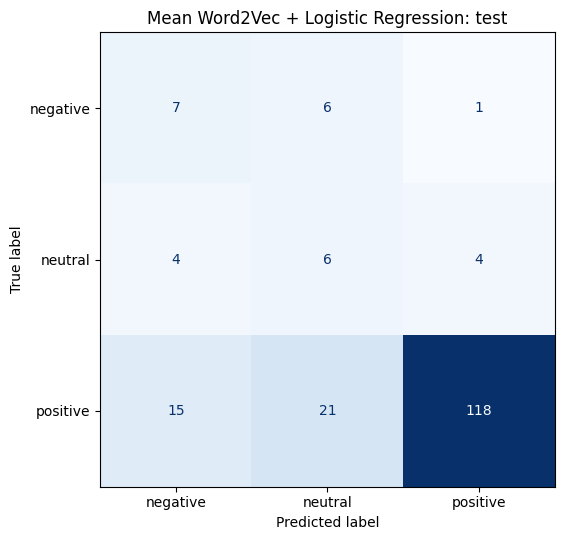

In [36]:
print(classification_report(
    y_test, pred_test, labels=[0, 1, 2], target_names=LABELS, zero_division=0
))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=[0, 1, 2], display_labels=LABELS,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Mean Word2Vec + Logistic Regression: test")
fig.tight_layout()
fig.savefig(FIG_DIR / "word2vec_mean_logreg_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

#### Вывод по Mean Pooling

Получено **Test Macro F1 = 0,4858**, **Macro Precision = 0,4701**, **Macro Recall = 0,5649**, **Accuracy = 71,98%**. Простое среднее векторов уже позволяет различать часть редких классов, но не сохраняет порядок слов, конструкцию отрицания и связи между аспектами отзыва.

Разница между обучающим и валидационным качеством показывает, что модель не полностью обобщает закономерности на новые тексты. Мы будем использовать этот результат как промежуточный baseline для BiLSTM и BERT.

#### Сравнение с классификатором большинства

DummyClassifier нужен как контроль: он вообще не анализирует текст, а всегда выбирает наиболее частый класс. При перекосе в пользу положительных отзывов такой алгоритм может иметь высокую Accuracy, поэтому покажем его Macro F1 отдельно.

In [37]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

comparison_df = pd.DataFrame([
    {"model": "Majority class (Dummy)", **evaluate_predictions(y_test, dummy_pred, "test")},
    {"model": "Mean Word2Vec + Logistic Regression", **evaluate_predictions(y_test, pred_test, "test")},
])
display(comparison_df.round(4))

,model,split,n_samples,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Majority class (Dummy),test,182,0.8462,0.2821,0.3333,0.3056,0.7756
1,Mean Word2Vec + Logistic Regression,test,182,0.7198,0.4701,0.5649,0.4858,0.7675


#### Почему Accuracy недостаточно

DummyClassifier всегда выбирает `positive`. На тесте это даёт **84,62% Accuracy**, но только **0,3056 Macro F1**. У логистической регрессии Accuracy ниже, зато Macro F1 выше — она хотя бы частично распознаёт негативные и нейтральные отзывы.

#### Сохраним baseline для общего сравнения

Запишем обученный классификатор, метрики и параметры эксперимента в `models/` и `results/`. Время логистической регрессии будем отличать от времени обучения Word2Vec и получения плотных векторов — это разные этапы вычислений.

In [38]:
joblib.dump(best_logreg, MODEL_DIR / "amazon_mean_w2v_logreg.joblib")
metrics_df.to_csv(RESULTS_DIR / "word2vec_mean_logreg_metrics.csv", index=False, encoding="utf-8-sig")
comparison_df.to_csv(RESULTS_DIR / "word2vec_mean_logreg_vs_dummy.csv", index=False, encoding="utf-8-sig")

In [39]:
benchmark_row = {
    "model": "Mean Word2Vec + Logistic Regression",
    "representation": "Word2Vec Skip-gram 100d / mean pooling",
    "classes": "1–2 negative, 3 neutral, 4–5 positive",
    "precision_macro": float(metrics_df.loc[metrics_df.split == "test", "precision_macro"].iloc[0]),
    "recall_macro": float(metrics_df.loc[metrics_df.split == "test", "recall_macro"].iloc[0]),
    "f1_macro": float(metrics_df.loc[metrics_df.split == "test", "f1_macro"].iloc[0]),
    "f1_weighted": float(metrics_df.loc[metrics_df.split == "test", "f1_weighted"].iloc[0]),
    "accuracy": float(metrics_df.loc[metrics_df.split == "test", "accuracy"].iloc[0]),
    "word2vec_train_seconds": float(training_seconds),
    "feature_vectorization_seconds": float(vectorization_seconds),
    "logreg_fit_seconds": float(best_fit_seconds),
    "logreg_hyperparameter_search_seconds": float(search_seconds),
    "best_C": best_C,
    "train_n": len(train_df), "val_n": len(val_df), "test_n": len(test_df),
    "seed": SEED,
}

In [40]:
pd.DataFrame([benchmark_row]).to_csv(
    RESULTS_DIR / "benchmark_step2.csv", index=False, encoding="utf-8-sig"
)
with (RESULTS_DIR / "benchmark_step2.json").open("w", encoding="utf-8") as f:
    json.dump(benchmark_row, f, indent=2, ensure_ascii=False)

print("Модель:", MODEL_DIR / "amazon_mean_w2v_logreg.joblib")
print("Метрики:", RESULTS_DIR / "word2vec_mean_logreg_metrics.csv")
print("Строка бенчмарка:", RESULTS_DIR / "benchmark_step2.csv")

Модель: models\amazon_mean_w2v_logreg.joblib
Метрики: results\word2vec_mean_logreg_metrics.csv
Строка бенчмарка: results\benchmark_step2.csv


### Шаги 3–4. Рекуррентная сеть BiLSTM: Static и Dynamic

В отличие от усреднения Word2Vec, рекуррентная сеть обрабатывает **последовательность** токенов. Двунаправленная LSTM проходит её слева направо и справа налево, что позволяет учитывать контекст до и после текущего слова.

Проверим два режима **одной и той же архитектуры**:

- **Static:** `Embedding` инициализирован нашим Word2Vec и **заморожен** (`requires_grad=False`).
- **Dynamic:** `Embedding` инициализируется случайно и **обучается с нуля** (`requires_grad=True`).

Гиперпараметры сети, разделение корпуса и метод оценки оставляем одинаковыми. Контролируем Train/Validation Loss и Macro F1, сохраняем лучшую модель по Validation Macro F1 и используем Early Stopping. Отзывы длиннее 160 токенов усекаем.

#### Подготовим PyTorch и устройство

Импортируем PyTorch, задаём генераторы случайных чисел и проверяем доступность CUDA. Остальные ячейки используют единые параметры сети для Static и Dynamic, чтобы различие было связано именно с режимом Embedding.

In [41]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

In [42]:
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_LENGTH = 160
EMB_DIM = w2v.vector_size
HIDDEN_DIM = 64
BATCH_SIZE = 32
MAX_EPOCHS = 15
PATIENCE = 3
MIN_DELTA = 1e-4
LEARNING_RATE = 1e-3
DROPOUT = 0.35

In [43]:
print("PyTorch:", torch.__version__)
print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Train/Val/Test:", len(train_df), len(val_df), len(test_df))
print("Максимальная длина последовательности:", MAX_LENGTH)

PyTorch: 2.6.0+cpu
Устройство: cpu
Train/Val/Test: 580 145 182
Максимальная длина последовательности: 160


#### Словарь и батчи последовательностей

В отличие от Mean Pooling, BiLSTM должна получить **порядок слов**. Строим словарь по обучающим токенам, добавляем специальные индексы для padding и неизвестных слов, кодируем отзывы и готовим DataLoader с длинами последовательностей.

In [44]:
# Проверяем, что последовательности совпадают с сохраненными разбиениями
assert len(train_tokens) == len(train_df)
assert len(val_tokens) == len(val_df)
assert len(test_tokens) == len(test_df)
assert set(np.unique(y_train)) == {0, 1, 2}

PAD_ID, UNK_ID = 0, 1
token_to_id = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for word in w2v.wv.index_to_key:
    token_to_id[word] = len(token_to_id)

VOCAB_SIZE = len(token_to_id)

In [45]:
def encode_sequence(tokens):
    if len(tokens) > MAX_LENGTH:
        left = MAX_LENGTH // 2
        tokens = tokens[:left] + tokens[-(MAX_LENGTH - left):]
    ids = [token_to_id.get(token, UNK_ID) for token in tokens]
    return ids or [UNK_ID]  # LSTM не может принять последовательность нулевой длины.

encoded_train = [encode_sequence(x) for x in train_tokens]
encoded_val = [encode_sequence(x) for x in val_tokens]
encoded_test = [encode_sequence(x) for x in test_tokens]

In [46]:
class ReviewSequenceDataset(Dataset):
    def __init__(self, encoded, targets):
        self.encoded = encoded
        self.targets = np.asarray(targets, dtype=np.int64)
        assert len(self.encoded) == len(self.targets)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.encoded[index], int(self.targets[index])

In [47]:
def pad_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
    x = pad_sequence([torch.tensor(s, dtype=torch.long) for s in sequences],
                     batch_first=True, padding_value=PAD_ID)
    y = torch.tensor(labels, dtype=torch.long)
    return x, lengths, y

train_data = ReviewSequenceDataset(encoded_train, y_train)
val_data = ReviewSequenceDataset(encoded_val, y_val)
test_data = ReviewSequenceDataset(encoded_test, y_test)

In [48]:
# Генератор DataLoader фиксирует порядок перемешивания независимо от глобального RNG
def make_train_loader():
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      collate_fn=pad_batch, num_workers=0, generator=generator)

train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False,
                               collate_fn=pad_batch, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False,
                        collate_fn=pad_batch, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False,
                         collate_fn=pad_batch, num_workers=0)

In [49]:
# Эту матрицу использует только Static, динамический Embedding будет инициализирован случайно
pretrained_matrix = np.zeros((VOCAB_SIZE, EMB_DIM), dtype=np.float32)
for word, idx in token_to_id.items():
    if word in w2v.wv:
        pretrained_matrix[idx] = w2v.wv[word]
# OOV-слово в Static задаем средним вектором словаря, а не нулем
pretrained_matrix[UNK_ID] = w2v.wv.vectors.mean(axis=0)
pretrained_matrix[PAD_ID] = 0.0
pretrained_tensor = torch.tensor(pretrained_matrix)

lengths = np.array([len(x) for x in train_tokens])
original_tokens = sum(map(len, train_tokens))
known_tokens = sum(t in w2v.wv for row in train_tokens for t in row)

In [50]:
print(f"Размер словаря (+ PAD, UNK): {VOCAB_SIZE}")
print(f"Доля токенов train в словаре: {known_tokens/max(1,original_tokens):.2%}")
print(f"Доля длинных отзывов train (> {MAX_LENGTH} токенов): {(lengths > MAX_LENGTH).mean():.2%}")
print(f"Средняя длина train: {lengths.mean():.1f}; медианная: {np.median(lengths):.0f}; максимум: {lengths.max()}")
print("Shapes одного батча:", [(tuple(z.shape)) for z in next(iter(make_train_loader()))])
assert pretrained_tensor.shape == (VOCAB_SIZE, EMB_DIM)

Размер словаря (+ PAD, UNK): 2033
Доля токенов train в словаре: 97.85%
Доля длинных отзывов train (> 160 токенов): 17.93%
Средняя длина train: 105.5; медианная: 34; максимум: 3465
Shapes одного батча: [(32, 160), (32,), (32,)]


#### Архитектура BiLSTM и режимы Embedding

Опишем класс `BiLSTMSentiment`: слой Embedding, двунаправленная LSTM, dropout и классификационная голова. Для Static загружаются веса Word2Vec с отключёнными градиентами. Dynamic обучает Embedding с нуля. Размерность выхода BiLSTM удваивается за счёт двух направлений.

In [51]:
class BiLSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes,
                 dropout, pretrained_weights=None):
        super().__init__()
        self.lstm = nn.LSTM(input_size=embed_dim, hidden_size=hidden_dim,
                            num_layers=1, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)
        if pretrained_weights is None:
            # Dynamic: случайные обучаемые эмбеддинги
            self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        else:
            # Static: перенесенные из Word2Vec веса, requires_grad=False
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_weights.clone(), freeze=True, padding_idx=PAD_ID
            )

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        # При одном слое bidirectional: hidden[-2] = forward, hidden[-1] = backward
        features = torch.cat((hidden[-2], hidden[-1]), dim=1)
        logits = self.classifier(self.dropout(features))
        return logits

In [52]:
def build_bilstm(mode):
    assert mode in ("static", "dynamic")
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    model = BiLSTMSentiment(
        vocab_size=VOCAB_SIZE, embed_dim=EMB_DIM, hidden_dim=HIDDEN_DIM,
        n_classes=len(LABELS), dropout=DROPOUT,
        pretrained_weights=pretrained_tensor if mode == "static" else None,
    ).to(DEVICE)
    emb_grad = model.embedding.weight.requires_grad
    assert emb_grad == (mode == "dynamic"), "Ошибка настройки Embedding"
    return model

In [53]:
for mode in ("static", "dynamic"):
    model_check = build_bilstm(mode)
    n_trainable = sum(p.numel() for p in model_check.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model_check.parameters())
    print(f"{mode:7s}: всего параметров {n_total:,}, обучаемых {n_trainable:,}, "
          f"Embedding requires_grad={model_check.embedding.weight.requires_grad}")
    with torch.no_grad():
        ids, lens, labels = next(iter(val_loader))
        logits = model_check(ids.to(DEVICE), lens)
        assert logits.shape == (len(labels), 3)

static : всего параметров 288,679, обучаемых 85,379, Embedding requires_grad=False
dynamic: всего параметров 288,679, обучаемых 288,679, Embedding requires_grad=True


#### Взвешенная функция потерь и Early Stopping

Сначала рассчитаем веса классов по **Train**, чтобы редкие метки влияли на ошибку сильнее. Затем опишем один проход по DataLoader, обучение по эпохам, контроль Validation Macro F1 и восстановление лучшего checkpoint. Графики и Test не участвуют в выборе лучших весов.

In [54]:
counts = np.bincount(y_train, minlength=len(LABELS))
class_weights = np.sqrt(len(y_train) / (len(LABELS) * counts))
class_weights = class_weights / class_weights.mean()
loss_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print(pd.DataFrame({"class": LABELS, "train_count": counts,
                    "loss_weight": class_weights.round(4)}).to_string(index=False))

   class  train_count  loss_weight
negative           46       1.2944
 neutral           45       1.3087
positive          489       0.3970


#### Как точно усреднять взвешенный Loss

`CrossEntropyLoss(weight=..., reduction="mean")` делит сумму взвешенных ошибок не на число объектов, а на **сумму весов их целевых классов**. Поэтому для каждой эпохи мы складываем `loss_батча × сумму_весов_батча` и делим на общую сумму весов всех батчей. Эта функция одинаково используется в BiLSTM, BERT v1 и BERT v2.

In [55]:
def weighted_ce_batch_parts(batch_loss, targets, loss_fn):
    """Числитель и знаменатель взвешенного CE для объединения батчей"""
    if loss_fn.reduction != "mean":
        raise ValueError("Ожидается CrossEntropyLoss(reduction='mean')")
    valid = targets != loss_fn.ignore_index
    if loss_fn.weight is None:
        denominator = float(valid.sum().item())
    else:
        denominator = float(loss_fn.weight[targets[valid]].detach().sum().item())
    numerator = float(batch_loss.detach().item()) * denominator
    return numerator, denominator

In [56]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, total_weight = 0.0, 0.0
    actual, predicted = [], []
    for x, lengths, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(x, lengths)
            loss = loss_fn(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
        batch_loss_sum, batch_weight = weighted_ce_batch_parts(loss, y, loss_fn)
        total_loss += batch_loss_sum
        total_weight += batch_weight
        actual.extend(y.detach().cpu().tolist())
        predicted.extend(logits.detach().argmax(dim=1).cpu().tolist())
    return {
        "loss": total_loss / max(1e-12, total_weight),
        "macro_f1": f1_score(actual, predicted, labels=[0, 1, 2],
                              average="macro", zero_division=0),
        "y_true": actual,
        "y_pred": predicted,
    }

In [57]:
def _bilstm_fit_epochs(mode, model, train_loader, loss_fn, optimizer):
    history, best_f1, best_epoch = [], -1.0, 0
    best_state, stale_epochs = None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_stats = run_epoch(model, train_loader, loss_fn, optimizer=optimizer)
        val_stats = run_epoch(model, val_loader, loss_fn)
        epoch_time = time.perf_counter() - epoch_start
        history.append({
            "epoch": epoch, "train_loss": train_stats["loss"],
            "validation_loss": val_stats["loss"],
            "train_f1_macro": train_stats["macro_f1"],
            "validation_f1_macro": val_stats["macro_f1"],
            "epoch_seconds": epoch_time,
        })
        print(f"{mode.capitalize():7s} | эпоха {epoch:02d}/{MAX_EPOCHS} "
              f"| loss {train_stats['loss']:.4f}/{val_stats['loss']:.4f} "
              f"| Macro F1 {train_stats['macro_f1']:.4f}/{val_stats['macro_f1']:.4f} "
              f"| {epoch_time:.1f} с", flush=True)
        if val_stats["macro_f1"] > best_f1 + MIN_DELTA:
            best_f1, best_epoch = val_stats["macro_f1"], epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print(f"Early Stopping: нет улучшения {PATIENCE} эпохи подряд.")
                break
    return history, best_f1, best_epoch, best_state

In [58]:
def _save_bilstm(mode, best_state, best_epoch, history):
    model_path = MODEL_DIR / f"amazon_bilstm_{mode}.pt"
    torch.save({
        "model_state_dict": best_state, "token_to_id": token_to_id,
        "labels": LABELS, "mode": mode, "max_length": MAX_LENGTH,
        "embedding_dim": EMB_DIM, "hidden_dim": HIDDEN_DIM,
        "dropout": DROPOUT, "best_epoch": best_epoch,
    }, model_path)
    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"bilstm_{mode}_history.csv",
                      index=False, encoding="utf-8-sig")
    return model_path, history_df

In [59]:
def fit_bilstm(mode):
    model = build_bilstm(mode)
    loss_fn = nn.CrossEntropyLoss(weight=loss_weights)
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad),
                                 lr=LEARNING_RATE)
    train_loader = make_train_loader()
    training_start = time.perf_counter()
    history, best_f1, best_epoch, best_state = _bilstm_fit_epochs(
        mode, model, train_loader, loss_fn, optimizer
    )
    seconds = time.perf_counter() - training_start
    assert best_state is not None
    model.load_state_dict(best_state)
    model_path, history_df = _save_bilstm(mode, best_state, best_epoch, history)
    print(f"{mode.capitalize()}: лучшая эпоха {best_epoch}, "
          f"validation Macro F1={best_f1:.4f}, "
          f"всего {len(history_df)} эпох, {seconds:.1f} с")
    return model, history_df, {
        "mode": mode, "best_epoch": best_epoch, "best_validation_f1": best_f1,
        "epochs_run": len(history_df), "training_seconds": seconds,
        "model_path": str(model_path),
    }

#### Обучим две версии BiLSTM

Запускаем `fit_bilstm` отдельно для Static и Dynamic и сохраняем истории потерь и метрик. Все другие параметры архитектуры фиксированы, время обучения каждой версии измеряется отдельно.

In [60]:
rnn_models = {}
rnn_histories = {}
rnn_training_info = {}
for mode in ("static", "dynamic"):
    trained, history, info = fit_bilstm(mode)
    rnn_models[mode] = trained
    rnn_histories[mode] = history
    rnn_training_info[mode] = info

Static  | эпоха 01/15 | loss 0.9886/0.9346 | Macro F1 0.3243/0.3046 | 15.0 с
Static  | эпоха 02/15 | loss 0.9096/0.9110 | Macro F1 0.3050/0.3046 | 3.8 с
Static  | эпоха 03/15 | loss 0.8917/0.8955 | Macro F1 0.3050/0.3046 | 2.8 с
Static  | эпоха 04/15 | loss 0.8450/0.8860 | Macro F1 0.3050/0.3046 | 2.8 с
Early Stopping: нет улучшения 3 эпохи подряд.
Static: лучшая эпоха 1, validation Macro F1=0.3046, всего 4 эпох, 24.4 с
Dynamic | эпоха 01/15 | loss 1.0236/0.9731 | Macro F1 0.3779/0.3030 | 2.8 с
Dynamic | эпоха 02/15 | loss 0.8654/0.9485 | Macro F1 0.3578/0.3046 | 2.8 с
Dynamic | эпоха 03/15 | loss 0.7809/0.9441 | Macro F1 0.3333/0.3046 | 15.5 с
Dynamic | эпоха 04/15 | loss 0.7062/0.9422 | Macro F1 0.4366/0.3058 | 4.6 с
Dynamic | эпоха 05/15 | loss 0.6023/0.9652 | Macro F1 0.6255/0.3557 | 3.5 с
Dynamic | эпоха 06/15 | loss 0.4907/0.9250 | Macro F1 0.7424/0.4696 | 3.0 с
Dynamic | эпоха 07/15 | loss 0.4193/0.9792 | Macro F1 0.8305/0.4651 | 2.9 с
Dynamic | эпоха 08/15 | loss 0.3149/1.0111 

#### Что сравниваем между Static и Dynamic

В обеих версиях одинаковая рекуррентная архитектура и общий Train/Validation/Test. Отличается только источник и обучаемость слоя Embedding. Поэтому разницу в результатах можно обсуждать как эффект режима представления слов в пределах одного запуска, но нельзя распространять на все варианты рекуррентных сетей.

#### Графики Loss и Macro F1

Для каждой версии построим две кривые: Loss показывает ошибку функции потерь, Macro F1 — качество трёх классов с одинаковым весом. Сильный разрыв между Train и Validation, особенно при падении Train Loss, будет сигналом переобучения.

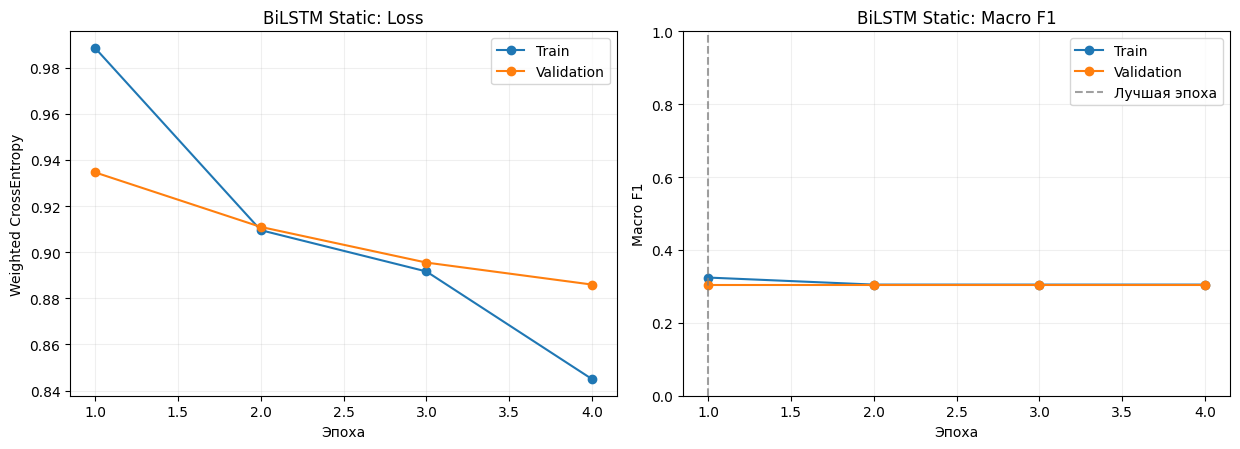

Сохранён график: figures\bilstm_static_learning_curves.png


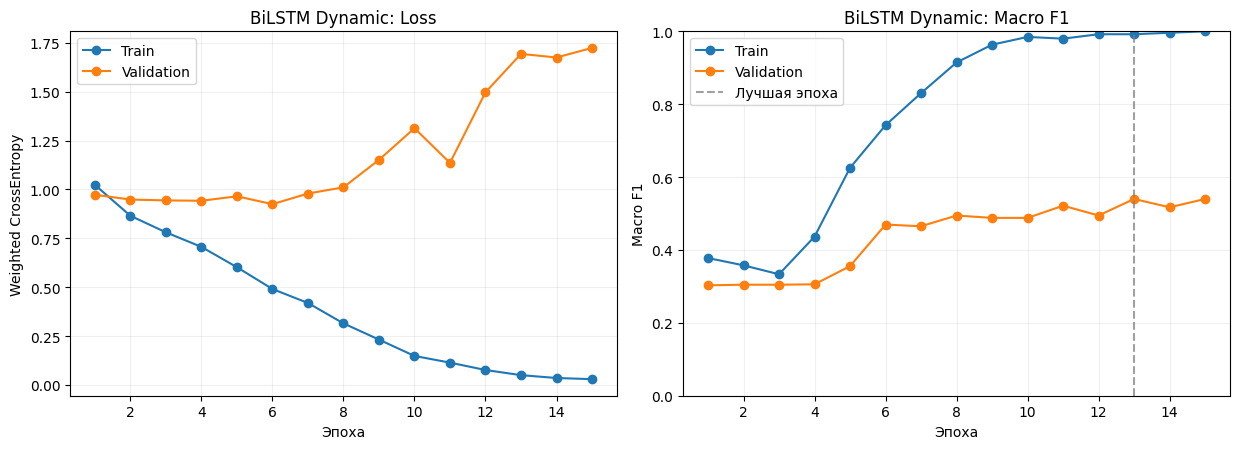

Сохранён график: figures\bilstm_dynamic_learning_curves.png


In [61]:
for mode in ("static", "dynamic"):
    hist = rnn_histories[mode]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    axes[0].plot(hist["epoch"], hist["train_loss"], "o-", label="Train")
    axes[0].plot(hist["epoch"], hist["validation_loss"], "o-", label="Validation")
    axes[0].set_title(f"BiLSTM {mode.capitalize()}: Loss")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Weighted CrossEntropy")
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(hist["epoch"], hist["train_f1_macro"], "o-", label="Train")
    axes[1].plot(hist["epoch"], hist["validation_f1_macro"], "o-", label="Validation")
    axes[1].axvline(rnn_training_info[mode]["best_epoch"], color="gray",
                    linestyle="--", alpha=0.75, label="Лучшая эпоха")
    axes[1].set_title(f"BiLSTM {mode.capitalize()}: Macro F1")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Macro F1")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.2)
    fig.tight_layout()
    fig_path = FIG_DIR / f"bilstm_{mode}_learning_curves.png"
    fig.savefig(fig_path, dpi=170, bbox_inches="tight")
    plt.show()
    print("Сохранён график:", fig_path)

#### Разбор графиков BiLSTM

**Static:** лучший checkpoint — первая эпоха, остановка после четвёртой. **Test Macro F1 = 0,3056**. Модель практически следовала самому частому классу.

**Dynamic:** на Train достигнут Macro F1 = **1,0**, но на Test только **0,3312**, несмотря на Validation Macro F1 = **0,5400**. По мере обучения Validation Loss рос при уменьшении Train Loss. Это характерная картина переобучения на малой выборке.

#### Test-метрики и матрицы ошибок BiLSTM

Оценим уже выбранные checkpoints на Train, Validation и Test. Для Test получим `classification_report` по каждому классу и матрицу ошибок. Так видно, не скрывает ли высокая Accuracy стратегию «всегда positive».

In [62]:
rnn_metric_rows = []
rnn_test_predictions = {}
rnn_test_reports = {}

In [63]:
def _report_rnn_test(mode, label, stats):
    report = classification_report(
        stats["y_true"], stats["y_pred"], labels=[0, 1, 2],
        target_names=LABELS, zero_division=0, output_dict=True
    )
    print(f"\n{label}: test classification_report")
    print(classification_report(
        stats["y_true"], stats["y_pred"], labels=[0, 1, 2],
        target_names=LABELS, zero_division=0
    ))
    pd.DataFrame(report).T.to_csv(
        RESULTS_DIR / f"bilstm_{mode}_classification_report.csv",
        encoding="utf-8-sig"
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        stats["y_true"], stats["y_pred"], labels=[0, 1, 2],
        display_labels=LABELS, cmap="Blues", ax=ax, colorbar=False,
        values_format="d"
    )
    ax.set_title(f"{label}: матрица ошибок (test)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"bilstm_{mode}_confusion_matrix.png",
                dpi=170, bbox_inches="tight")
    plt.show()
    return report


BiLSTM Static: test classification_report
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        14
     neutral       0.00      0.00      0.00        14
    positive       0.85      1.00      0.92       154

    accuracy                           0.85       182
   macro avg       0.28      0.33      0.31       182
weighted avg       0.72      0.85      0.78       182



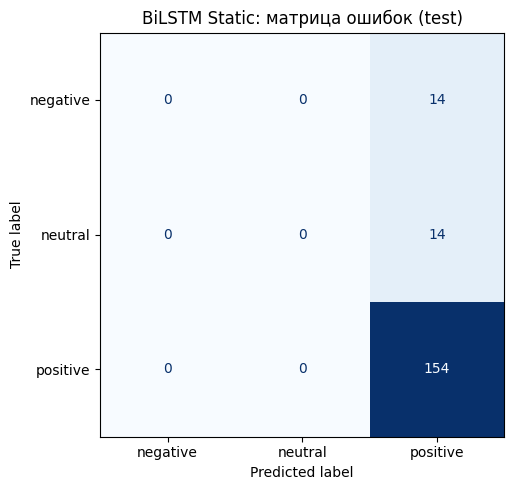


BiLSTM Dynamic: test classification_report
              precision    recall  f1-score   support

    negative       0.14      0.07      0.10        14
     neutral       0.00      0.00      0.00        14
    positive       0.85      0.95      0.90       154

    accuracy                           0.81       182
   macro avg       0.33      0.34      0.33       182
weighted avg       0.73      0.81      0.77       182



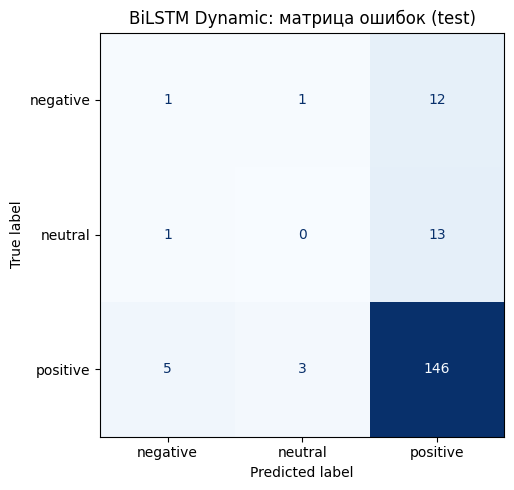

In [64]:
for mode in ("static", "dynamic"):
    model = rnn_models[mode]
    loss_fn = nn.CrossEntropyLoss(weight=loss_weights)
    label = f"BiLSTM {mode.capitalize()}"
    split_loaders = [
        ("train", train_eval_loader),
        ("validation", val_loader),
        ("test", test_loader),
    ]
    for split_name, loader in split_loaders:
        stats = run_epoch(model, loader, loss_fn)
        row = evaluate_predictions(stats["y_true"], stats["y_pred"], split_name)
        row.update({"model": label, "loss": stats["loss"]})
        rnn_metric_rows.append(row)
        if split_name == "test":
            rnn_test_predictions[mode] = stats["y_pred"]
            rnn_test_reports[mode] = _report_rnn_test(mode, label, stats)

In [65]:
rnn_metrics_df = pd.DataFrame(rnn_metric_rows)
rnn_metrics_df.to_csv(RESULTS_DIR / "bilstm_metrics.csv", index=False, encoding="utf-8-sig")
display(rnn_metrics_df[[
    "model", "split", "n_samples", "precision_macro", "recall_macro",
    "f1_macro", "f1_weighted", "accuracy", "loss"
]].round(4))

,model,split,n_samples,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy,loss
0,BiLSTM Static,train,580,0.2810,0.3333,0.3050,0.7713,0.8431,0.9157
1,BiLSTM Static,validation,145,0.2805,0.3333,0.3046,0.7689,0.8414,0.9346
2,BiLSTM Static,test,182,0.2821,0.3333,0.3056,0.7756,0.8462,0.9267
3,BiLSTM Dynamic,train,580,1.0000,1.0000,1.0000,1.0000,1.0000,0.0347
4,BiLSTM Dynamic,validation,145,0.6799,0.4889,0.5400,0.8267,0.8483,1.6938
5,BiLSTM Dynamic,test,182,0.3322,0.3398,0.3312,0.7676,0.8077,2.0063


#### Промежуточное сравнение RNN с baseline

Перенесём метрики BiLSTM в общую структуру бенчмарка и добавим результат Word2Vec + Logistic Regression.

In [66]:
rnn_test_metrics = rnn_metrics_df[rnn_metrics_df["split"] == "test"].copy()

step3_benchmark_rows = []

In [67]:
for mode in ("static", "dynamic"):
    row = rnn_test_metrics[rnn_test_metrics["model"] == f"BiLSTM {mode.capitalize()}"].iloc[0]
    info = rnn_training_info[mode]
    step3_benchmark_rows.append({
        "model": row["model"],
        "representation": (
            "Word2Vec 100d frozen + BiLSTM" if mode == "static"
            else "Random trainable embeddings 100d + BiLSTM"
        ),
        "classes": "1–2 negative, 3 neutral, 4–5 positive",
        "precision_macro": float(row["precision_macro"]),
        "recall_macro": float(row["recall_macro"]),
        "f1_macro": float(row["f1_macro"]),
        "f1_weighted": float(row["f1_weighted"]),
        "accuracy": float(row["accuracy"]),
        "training_seconds": float(info["training_seconds"]),
        "word2vec_train_seconds": float(training_seconds) if mode == "static" else 0.0,
        "best_epoch": int(info["best_epoch"]),
        "epochs_run": int(info["epochs_run"]),
        "train_n": len(train_df), "val_n": len(val_df), "test_n": len(test_df),
        "seed": SEED,
    })

In [68]:
step3_benchmark = pd.DataFrame(step3_benchmark_rows)
step3_benchmark.to_csv(RESULTS_DIR / "benchmark_step3.csv",
                       index=False, encoding="utf-8-sig")

base_row = pd.read_csv(RESULTS_DIR / "benchmark_step2.csv")
benchmark_so_far = pd.concat([base_row, step3_benchmark], ignore_index=True)
benchmark_so_far.to_csv(RESULTS_DIR / "benchmark_steps2_3.csv",
                        index=False, encoding="utf-8-sig")
display(benchmark_so_far[[
    "model", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "accuracy"
]].round(4).sort_values("f1_macro", ascending=False))

,model,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy
0,Mean Word2Vec + Logistic Regression,0.4701,0.5649,0.4858,0.7675,0.7198
2,BiLSTM Dynamic,0.3322,0.3398,0.3312,0.7676,0.8077
1,BiLSTM Static,0.2821,0.3333,0.3056,0.7756,0.8462


In [69]:
print("\nВремя обучения BiLSTM (без общих затрат на лемматизацию):")
for mode, info in rnn_training_info.items():
    print(f"{mode}: {info['training_seconds']:.1f} с, "
          f"лучшая эпоха {info['best_epoch']} из {info['epochs_run']}")
print("\nТаблица текущего бенчмарка:", RESULTS_DIR / "benchmark_steps2_3.csv")
print("Обученные модели:", MODEL_DIR / "amazon_bilstm_static.pt", "и",
      MODEL_DIR / "amazon_bilstm_dynamic.pt")


Время обучения BiLSTM (без общих затрат на лемматизацию):
static: 24.4 с, лучшая эпоха 1 из 4
dynamic: 58.9 с, лучшая эпоха 13 из 15

Таблица текущего бенчмарка: results\benchmark_steps2_3.csv
Обученные модели: models\amazon_bilstm_static.pt и models\amazon_bilstm_dynamic.pt


#### Промежуточный вывод по BiLSTM

Обе рекуррентные модели уступили Mean Word2Vec + Logistic Regression по Test Macro F1 (**0,4858**). Static обучалась **24,45 с**, Dynamic — **58,90 с**. Сложная архитектура пока не дала прироста качества на этом датасете, а Dynamic заметно переобучилась.

### Шаги 5–6. Fine-Tuning предобученного трансформера BERT

В задании приведены примеры `rubert` для русского языка. Наши отзывы **преимущественно англоязычные**, поэтому выбираем англоязычную предобученную модель [`prajjwal1/bert-tiny`](https://huggingface.co/prajjwal1/bert-tiny). У неё два трансформерных слоя и скрытая размерность 128 — она легче полноразмерного BERT для запуска на CPU.

Мы не просто извлекаем готовые эмбеддинги. Поверх трансформера создаётся **линейная классификационная голова на 3 класса**, после чего градиенты обновляют **все параметры** модели. Для токенизации используется WordPiece, а входы ограничиваются по длине.

Выбирать лучший checkpoint будем по **Validation Macro F1**, а на Test посмотрим только после завершения обучения. Классификационная голова инициализируется заново для трёх классов.

#### Библиотека Transformers

Для этого раздела нужны `transformers` версии 4.x (от 4.44) и `safetensors`.

#### Настройки эксперимента BERT

Чтобы BERT можно было запустить отдельно, считываем ранее сохранённые CSV-разбиения и заново устанавливаем случайные seed. Используем собственный объект настроек для устройства, длины последовательности, скорости обучения и Early Stopping.

In [70]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [71]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DATA_DIR, MODEL_DIR, FIG_DIR, RESULTS_DIR = (
    Path('data'), Path('models'), Path('figures'), Path('results')
)
for p in (DATA_DIR, MODEL_DIR, FIG_DIR, RESULTS_DIR):
    p.mkdir(exist_ok=True, parents=True)

LABELS = ['negative', 'neutral', 'positive']
LABEL_TO_ID = {name: idx for idx, name in enumerate(LABELS)}
BERT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [72]:
BERT_MODEL_NAME = 'prajjwal1/bert-tiny'
BERT_MAX_LENGTH = 160
BERT_BATCH_SIZE = 16
BERT_MAX_EPOCHS = 6
BERT_PATIENCE = 2
BERT_MIN_DELTA = 1e-4
BERT_LEARNING_RATE = 5e-5
BERT_WEIGHT_DECAY = 0.01

required_splits = {k: DATA_DIR / f'lab4_{k}.csv' for k in ('train', 'val', 'test')}
missing = [str(p) for p in required_splits.values() if not p.exists()]

In [73]:
if missing:
    raise FileNotFoundError(
        'Не найдены сохранённые выборки: ' + ', '.join(missing) +
        '. Выполните сначала ячейку разделения данных (четвёртую) в этой папке проекта.'
    )

bert_train_df = pd.read_csv(required_splits['train'])
bert_val_df = pd.read_csv(required_splits['val'])
bert_test_df = pd.read_csv(required_splits['test'])
for part in (bert_train_df, bert_val_df, bert_test_df):
    assert {'Text', 'target'}.issubset(part.columns)
    assert part['Text'].notna().all()
    part['target'] = part['target'].astype(int)

In [74]:
assert (len(bert_train_df), len(bert_val_df), len(bert_test_df)) == (580, 145, 182)
assert not (set(bert_train_df.Text) & set(bert_val_df.Text))
assert not (set(bert_train_df.Text) & set(bert_test_df.Text))
assert not (set(bert_val_df.Text) & set(bert_test_df.Text))
for part in (bert_train_df, bert_val_df, bert_test_df):
    assert set(part['target'].unique()) == {0, 1, 2}

print('Transformers:', transformers.__version__)
print('PyTorch:', torch.__version__)
print('Устройство:', BERT_DEVICE)
print('Модель:', BERT_MODEL_NAME)
print('Train/Validation/Test:', len(bert_train_df), len(bert_val_df), len(bert_test_df))

Transformers: 4.49.0
PyTorch: 2.6.0+cpu
Устройство: cpu
Модель: prajjwal1/bert-tiny
Train/Validation/Test: 580 145 182


In [75]:
print(pd.DataFrame({
    'train': bert_train_df.target.value_counts().reindex(range(3), fill_value=0).to_numpy(),
    'validation': bert_val_df.target.value_counts().reindex(range(3), fill_value=0).to_numpy(),
    'test': bert_test_df.target.value_counts().reindex(range(3), fill_value=0).to_numpy(),
}, index=LABELS).to_string())

          train  validation  test
negative     46          12    14
neutral      45          11    14
positive    489         122   154


#### WordPiece-токенизация и DataLoader

Токенизатор предобученного BERT преобразует слова в subword-токены и добавляет служебные специальные токены. Формируем батчи с attention mask и динамическим padding. Метки передаём отдельно, чтобы явно считать взвешенную функцию потерь.

In [76]:
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME, use_fast=True)

In [77]:
class BertReviewsDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length):
        texts = frame['Text'].astype(str).tolist()
        self.labels = frame['target'].astype(int).tolist()
        self.encodings = tokenizer(
            texts, truncation=True, max_length=max_length, padding=False
        )
        assert len(self.labels) == len(self.encodings['input_ids'])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: value[idx] for k, value in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

In [78]:
bert_train_data = BertReviewsDataset(bert_train_df, bert_tokenizer, BERT_MAX_LENGTH)
bert_val_data = BertReviewsDataset(bert_val_df, bert_tokenizer, BERT_MAX_LENGTH)
bert_test_data = BertReviewsDataset(bert_test_df, bert_tokenizer, BERT_MAX_LENGTH)
bert_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer, return_tensors='pt')

bert_train_loader = DataLoader(
    bert_train_data, batch_size=BERT_BATCH_SIZE, shuffle=True,
    collate_fn=bert_collator, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

In [79]:
bert_train_eval_loader = DataLoader(
    bert_train_data, batch_size=BERT_BATCH_SIZE, shuffle=False,
    collate_fn=bert_collator, num_workers=0,
)
bert_val_loader = DataLoader(
    bert_val_data, batch_size=BERT_BATCH_SIZE, shuffle=False,
    collate_fn=bert_collator, num_workers=0,
)
bert_test_loader = DataLoader(
    bert_test_data, batch_size=BERT_BATCH_SIZE, shuffle=False,
    collate_fn=bert_collator, num_workers=0,
)

In [80]:
one_batch = next(iter(bert_train_loader))
print('Размеры одного батча:', {k: tuple(v.shape) for k, v in one_batch.items()})
print('Пример входа:', bert_tokenizer.convert_ids_to_tokens(bert_train_data[0]['input_ids'][:25]))
assert set(one_batch.keys()) >= {'input_ids', 'attention_mask', 'labels'}
assert one_batch['input_ids'].shape[0] <= BERT_BATCH_SIZE
assert one_batch['input_ids'].shape[1] <= BERT_MAX_LENGTH

Размеры одного батча: {'input_ids': (16, 160), 'token_type_ids': (16, 160), 'attention_mask': (16, 160), 'labels': (16,)}
Пример входа: ['[CLS]', 'tr', '##s', 'he', '##ure', '##ux', 'que', 'les', 'liv', '##res', 'so', '##ient', 'sur', 'ic', '##lou', '##d', '.', 'apr', '##s', 'm', "'", 'tre', 'fai', '##t', 'vol']


#### Классификационная голова и оптимизатор

`AutoModelForSequenceClassification` добавляет поверх BERT линейную голову на три класса. Проверим, что модель действительно содержит обучаемые параметры, и зададим AdamW. Веса редких классов вычисляем только по обучающей части.

In [81]:
def load_review_bert(*args, **kwargs):
    logger = logging.getLogger('transformers.modeling_utils')

    def keep_message(record):
        message = record.getMessage()
        expected_keys = "['classifier.bias', 'classifier.weight']"
        return not ('were not initialized from the model checkpoint' in message
                    and expected_keys in message)

    logger.addFilter(keep_message)
    try:
        return AutoModelForSequenceClassification.from_pretrained(*args, **kwargs)
    finally:
        logger.removeFilter(keep_message)

bert_model = load_review_bert(
    BERT_MODEL_NAME,
    num_labels=len(LABELS),
    id2label={i: name for i, name in enumerate(LABELS)},
    label2id=LABEL_TO_ID,
).to(BERT_DEVICE)

bert_counts = np.bincount(bert_train_df['target'].to_numpy(), minlength=len(LABELS))
bert_class_weights = np.sqrt(len(bert_train_df) / (len(LABELS) * bert_counts))
bert_class_weights = bert_class_weights / bert_class_weights.mean()
bert_loss_weights = torch.tensor(bert_class_weights, dtype=torch.float32, device=BERT_DEVICE)

In [82]:
bert_loss_fn = nn.CrossEntropyLoss(weight=bert_loss_weights)
bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(), lr=BERT_LEARNING_RATE, weight_decay=BERT_WEIGHT_DECAY
)

bert_total_parameters = sum(p.numel() for p in bert_model.parameters())
bert_trainable_parameters = sum(p.numel() for p in bert_model.parameters() if p.requires_grad)
assert bert_total_parameters == bert_trainable_parameters, 'Fine-tuning должен обновлять все слои BERT'
assert bert_model.config.num_labels == 3
assert bert_model.config.id2label == dict(enumerate(LABELS))

In [83]:
with torch.inference_mode():
    bert_model.eval()
    sample_logits = bert_model(**{
        key: value[:2].to(BERT_DEVICE)
        for key, value in one_batch.items() if key != 'labels'
    }).logits
assert tuple(sample_logits.shape) == (2, 3)

print(f'Параметров всего: {bert_total_parameters:,}, обучаемых: {bert_trainable_parameters:,}')
print('Веса классов:', dict(zip(LABELS, np.round(bert_class_weights, 4))))
print('Форма выхода модели:', tuple(sample_logits.shape))

Параметров всего: 4,386,307, обучаемых: 4,386,307
Веса классов: {'negative': 1.2944, 'neutral': 1.3087, 'positive': 0.397}
Форма выхода модели: (2, 3)


#### Цикл Fine-Tuning и выбор лучшей эпохи

Один проход по батчам считает loss и Macro F1, при обучении обновляя параметры по градиентам. После каждой эпохи сравниваем Validation Macro F1 с лучшим результатом. Когда улучшений нет заданное число эпох, останавливаем обучение и восстанавливаем лучшие веса.

In [84]:
def bert_run_epoch(model, loader, loss_fn, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    losses, total_weight = 0.0, 0.0
    y_true_all, y_pred_all = [], []
    for batch in loader:
        targets = batch['labels'].to(BERT_DEVICE)
        inputs = {key: value.to(BERT_DEVICE) for key, value in batch.items() if key != 'labels'}
        with torch.set_grad_enabled(is_train):
            logits = model(**inputs).logits
            loss = loss_fn(logits, targets)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
        batch_sum, batch_weight = weighted_ce_batch_parts(loss, targets, loss_fn)
        losses += batch_sum
        total_weight += batch_weight
        y_true_all.extend(targets.cpu().tolist())
        y_pred_all.extend(logits.detach().argmax(dim=-1).cpu().tolist())
    return {
        'loss': losses / max(total_weight, 1e-12),
        'macro_f1': f1_score(y_true_all, y_pred_all, average='macro', labels=[0, 1, 2], zero_division=0),
        'y_true': y_true_all,
        'y_pred': y_pred_all,
    }

In [85]:
bert_history = []
bert_best_f1 = -1.0
bert_best_epoch = 0
bert_best_state = None
bert_stale_epochs = 0
bert_start = time.perf_counter()

In [86]:
for epoch in range(1, BERT_MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_result = bert_run_epoch(bert_model, bert_train_loader, bert_loss_fn, bert_optimizer)
    validation_result = bert_run_epoch(bert_model, bert_val_loader, bert_loss_fn)
    if BERT_DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    epoch_seconds = time.perf_counter() - epoch_start
    bert_history.append({
        'epoch': epoch,
        'train_loss': train_result['loss'],
        'validation_loss': validation_result['loss'],
        'train_f1_macro': train_result['macro_f1'],
        'validation_f1_macro': validation_result['macro_f1'],
        'epoch_seconds': epoch_seconds,
    })
    print(
        f'BERT | эпоха {epoch:02d}/{BERT_MAX_EPOCHS} | '
        f'Loss train/val {train_result["loss"]:.4f}/{validation_result["loss"]:.4f} | '
        f'Macro F1 train/val {train_result["macro_f1"]:.4f}/{validation_result["macro_f1"]:.4f} | '
        f'{epoch_seconds:.1f} с', flush=True
    )
    if validation_result['macro_f1'] > bert_best_f1 + BERT_MIN_DELTA:
        bert_best_f1 = validation_result['macro_f1']
        bert_best_epoch = epoch
        bert_best_state = {name: value.detach().cpu().clone()
                           for name, value in bert_model.state_dict().items()}
        bert_stale_epochs = 0
    else:
        bert_stale_epochs += 1
        if bert_stale_epochs >= BERT_PATIENCE:
            print(f'Early Stopping: нет улучшений {BERT_PATIENCE} эпохи подряд.')
            break

BERT | эпоха 01/6 | Loss train/val 1.0153/0.9434 | Macro F1 train/val 0.3249/0.3046 | 18.7 с
BERT | эпоха 02/6 | Loss train/val 0.9384/0.9256 | Macro F1 train/val 0.3050/0.3046 | 8.4 с
BERT | эпоха 03/6 | Loss train/val 0.9208/0.9199 | Macro F1 train/val 0.3050/0.3046 | 4.3 с
Early Stopping: нет улучшений 2 эпохи подряд.


In [87]:
if BERT_DEVICE.type == 'cuda':
    torch.cuda.synchronize()
bert_training_seconds = time.perf_counter() - bert_start
assert bert_best_state is not None
bert_model.load_state_dict(bert_best_state)
bert_history_df = pd.DataFrame(bert_history)
bert_history_df.to_csv(RESULTS_DIR / 'bert_tiny_history.csv', index=False, encoding='utf-8-sig')

print(f'Лучшая эпоха: {bert_best_epoch}; лучший validation Macro F1: {bert_best_f1:.4f}')
print(f'Обучено эпох: {len(bert_history_df)}; время обучения: {bert_training_seconds:.1f} с')

Лучшая эпоха: 1; лучший validation Macro F1: 0.3046
Обучено эпох: 3; время обучения: 31.7 с


#### Что показывает исходное обучение BERT

Все параметры компактной BERT доступны для изменения, а качество каждого checkpoint контролируется на Validation. В сохранённом эксперименте лучшим оказался checkpoint **первой эпохи**. Если обучение быстро приводит к предсказанию большинства, это может отражать сильный дисбаланс, ограниченность небольшого корпуса и специфику весов классов.

#### Кривые обучения BERT

Построим те же графики, что для BiLSTM: Train/Validation Loss и Macro F1. Сравнение динамики помогает отличить недостаточное обучение от переобучения и объяснить выбор checkpoint.

In [88]:
def show_bert_v1_curves():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    axes[0].plot(bert_history_df['epoch'], bert_history_df['train_loss'], 'o-', label='Train')
    axes[0].plot(bert_history_df['epoch'], bert_history_df['validation_loss'], 'o-', label='Validation')
    axes[0].set_title('BERT-tiny Fine-Tuning: Loss')
    axes[0].set_xlabel('Эпоха')
    axes[0].set_ylabel('Weighted CrossEntropy')
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(bert_history_df['epoch'], bert_history_df['train_f1_macro'], 'o-', label='Train')
    axes[1].plot(bert_history_df['epoch'], bert_history_df['validation_f1_macro'], 'o-', label='Validation')
    axes[1].axvline(bert_best_epoch, linestyle='--', color='gray', label='Лучшая эпоха')
    axes[1].set_title('BERT-tiny Fine-Tuning: Macro F1')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel('Macro F1')
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.2)
    fig.tight_layout()
    bert_curves_path = FIG_DIR / 'bert_tiny_learning_curves.png'
    fig.savefig(bert_curves_path, dpi=170, bbox_inches='tight')
    plt.show()
    print('График:', bert_curves_path)

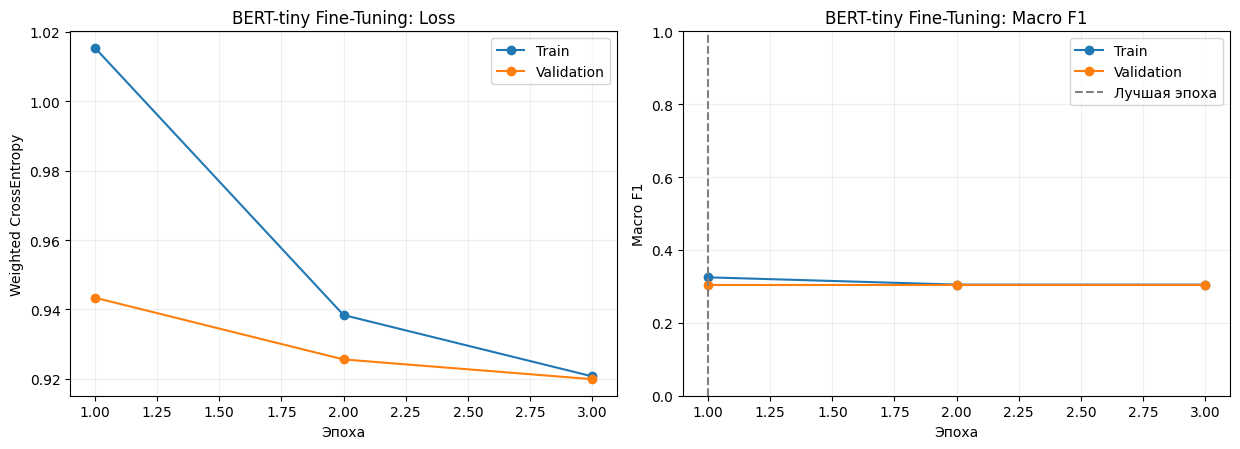

График: figures\bert_tiny_learning_curves.png


In [89]:
show_bert_v1_curves()

#### Проверка качества BERT на Test

Для выбранного по Validation checkpoint посчитаем метрики на всех трёх частях корпуса. На тесте дополнительно покажем `classification_report` и матрицу ошибок, чтобы отдельно оценить негативные и нейтральные отзывы.

In [90]:
def bert_evaluate_predictions(y_true, y_pred, split):
    precision, recall, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', labels=[0, 1, 2], zero_division=0
    )
    return {
        'split': split,
        'n_samples': len(y_true),
        'precision_macro': float(precision),
        'recall_macro': float(recall),
        'f1_macro': float(f1_macro),
        'f1_weighted': float(f1_score(y_true, y_pred, average='weighted', labels=[0, 1, 2], zero_division=0)),
        'accuracy': float(accuracy_score(y_true, y_pred)),
    }

In [91]:
bert_eval_rows = []
bert_test_result = None
for split, loader in [
    ('train', bert_train_eval_loader), ('validation', bert_val_loader), ('test', bert_test_loader)
]:
    result = bert_run_epoch(bert_model, loader, bert_loss_fn)
    row = bert_evaluate_predictions(result['y_true'], result['y_pred'], split)
    row['loss'] = result['loss']
    bert_eval_rows.append(row)
    if split == 'test':
        bert_test_result = result

bert_metrics_df = pd.DataFrame(bert_eval_rows)

In [92]:
bert_metrics_df.to_csv(RESULTS_DIR / 'bert_tiny_metrics.csv', index=False, encoding='utf-8-sig')
display(bert_metrics_df.round(4))

bert_report_text = classification_report(
    bert_test_result['y_true'], bert_test_result['y_pred'],
    labels=[0, 1, 2], target_names=LABELS, zero_division=0
)
print('\nBERT-tiny — classification_report на test:\n', bert_report_text)
bert_report_dict = classification_report(
    bert_test_result['y_true'], bert_test_result['y_pred'],
    labels=[0, 1, 2], target_names=LABELS, zero_division=0, output_dict=True
)

,split,n_samples,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy,loss
0,train,580,0.2810,0.3333,0.3050,0.7713,0.8431,0.9394
1,validation,145,0.2805,0.3333,0.3046,0.7689,0.8414,0.9434
2,test,182,0.2821,0.3333,0.3056,0.7756,0.8462,0.9403



BERT-tiny — classification_report на test:
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00        14
     neutral       0.00      0.00      0.00        14
    positive       0.85      1.00      0.92       154

    accuracy                           0.85       182
   macro avg       0.28      0.33      0.31       182
weighted avg       0.72      0.85      0.78       182



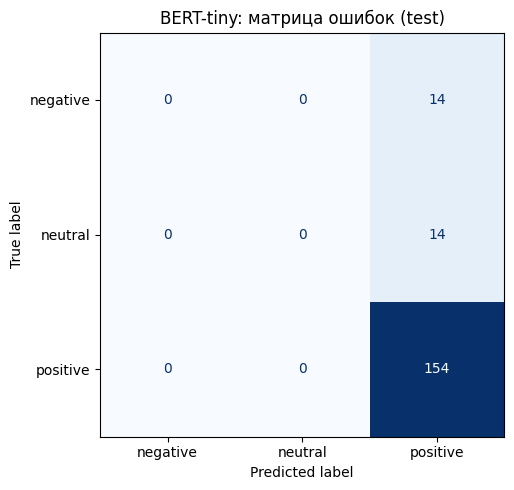

In [93]:
pd.DataFrame(bert_report_dict).T.to_csv(
    RESULTS_DIR / 'bert_tiny_classification_report.csv', encoding='utf-8-sig'
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    bert_test_result['y_true'], bert_test_result['y_pred'],
    labels=[0, 1, 2], display_labels=LABELS,
    cmap='Blues', colorbar=False, values_format='d', ax=ax,
)
ax.set_title('BERT-tiny: матрица ошибок (test)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'bert_tiny_confusion_matrix.png', dpi=170, bbox_inches='tight')
plt.show()

#### Вывод по BERT v1

На Test получен **Macro F1 = 0,3056** и **Accuracy = 84,62%**. Однако `classification_report` показывает **нулевые F1 для negative и neutral**: модель предсказала только `positive`. Высокая Accuracy в данном случае не означает качественную трёхклассовую классификацию. Обучение заняло **31,73 с**.

#### Сохранение исходной BERT и результатов

Сохраним веса и токенизатор в отдельной папке. Добавим BERT в текущую таблицу. В общей структуре обязательно укажем Macro Precision/Recall/F1, Accuracy и время обучения.

In [94]:
bert_save_dir = MODEL_DIR / 'amazon_bert_tiny_finetuned'
bert_save_dir.mkdir(exist_ok=True, parents=True)
bert_model.save_pretrained(bert_save_dir)
bert_tokenizer.save_pretrained(bert_save_dir)

bert_test_row = bert_metrics_df.loc[bert_metrics_df['split'] == 'test'].iloc[0]

In [95]:
bert_benchmark_row = {
    'model': 'BERT-tiny Fine-Tuning',
    'representation': 'prajjwal1/bert-tiny, WordPiece, pretrained BERT + linear head',
    'classes': '1–2 negative, 3 neutral, 4–5 positive',
    'precision_macro': float(bert_test_row['precision_macro']),
    'recall_macro': float(bert_test_row['recall_macro']),
    'f1_macro': float(bert_test_row['f1_macro']),
    'f1_weighted': float(bert_test_row['f1_weighted']),
    'accuracy': float(bert_test_row['accuracy']),
    'training_seconds': float(bert_training_seconds),
    'best_epoch': int(bert_best_epoch),
    'epochs_run': int(len(bert_history_df)),
    'train_n': len(bert_train_df),
    'val_n': len(bert_val_df),
    'test_n': len(bert_test_df),
    'seed': SEED,
}

In [96]:
pd.DataFrame([bert_benchmark_row]).to_csv(
    RESULTS_DIR / 'benchmark_step4_bert.csv', index=False, encoding='utf-8-sig'
)

previous_benchmark_path = RESULTS_DIR / 'benchmark_steps2_3.csv'
if previous_benchmark_path.exists():
    bert_all_benchmark = pd.concat(
        [pd.read_csv(previous_benchmark_path), pd.DataFrame([bert_benchmark_row])],
        ignore_index=True
    )
    print('Бенчмарк Word2Vec, BiLSTM и BERT:')
else:
    bert_all_benchmark = pd.DataFrame([bert_benchmark_row])
    print('Таблица предыдущих моделей не найдена, сохранён только результат BERT.')

Бенчмарк Word2Vec, BiLSTM и BERT:


In [97]:
bert_all_benchmark.to_csv(
    RESULTS_DIR / 'benchmark_steps2_6.csv', index=False, encoding='utf-8-sig'
)
display(bert_all_benchmark[
    ['model', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'accuracy']
].sort_values('f1_macro', ascending=False).round(4))

,model,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy
0,Mean Word2Vec + Logistic Regression,0.4701,0.5649,0.4858,0.7675,0.7198
2,BiLSTM Dynamic,0.3322,0.3398,0.3312,0.7676,0.8077
1,BiLSTM Static,0.2821,0.3333,0.3056,0.7756,0.8462
3,BERT-tiny Fine-Tuning,0.2821,0.3333,0.3056,0.7756,0.8462


In [98]:
with (RESULTS_DIR / 'bert_tiny_config.json').open('w', encoding='utf-8') as f:
    json.dump({
        'model_name': BERT_MODEL_NAME, 'max_length': BERT_MAX_LENGTH,
        'batch_size': BERT_BATCH_SIZE, 'max_epochs': BERT_MAX_EPOCHS,
        'patience': BERT_PATIENCE, 'learning_rate': BERT_LEARNING_RATE,
        'weight_decay': BERT_WEIGHT_DECAY, 'class_weights': bert_class_weights.tolist(),
        'best_epoch': bert_best_epoch, 'training_seconds': bert_training_seconds,
        'device': str(BERT_DEVICE), 'seed': SEED,
        'train_n': len(bert_train_df), 'val_n': len(bert_val_df), 'test_n': len(bert_test_df),
    }, f, ensure_ascii=False, indent=2)

print('Модель и токенизатор:', bert_save_dir)
print('Метрики:', RESULTS_DIR / 'bert_tiny_metrics.csv')
print('Общий бенчмарк:', RESULTS_DIR / 'benchmark_steps2_6.csv')

Модель и токенизатор: models\amazon_bert_tiny_finetuned
Метрики: results\bert_tiny_metrics.csv
Общий бенчмарк: results\benchmark_steps2_6.csv


### Дополнительный эксперимент: BERT-tiny v2 и дисбаланс классов

У исходной модели BERT обнаружилось вырождение: она отнесла **все** тестовые отзывы к положительному классу. В качестве диагностического эксперимента повторно обучим ту же архитектуру, но с **более сильными обратными весами классов**, увеличим число эпох и порог ожидания Early Stopping.

#### Конфигурация повторного эксперимента

Во второй версии заново загружаем те же предобученные веса и отдельно устанавливаем seed. Меняется не архитектура, а режим учёта дисбаланса и параметры цикла обучения. Сохраняем результаты отдельно от первой версии.

In [99]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DATA_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR = map(Path, ('data', 'results', 'figures', 'models'))
for p in [DATA_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR]:
    p.mkdir(exist_ok=True, parents=True)
LABELS = ['negative','neutral','positive']
BERT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BERT_V2_MODEL = 'prajjwal1/bert-tiny'

In [100]:
BERT_V2_MAX_LENGTH = 160
BERT_V2_BATCH = 16
BERT_V2_LR = 5e-5
BERT_V2_WEIGHT_DECAY = 0.01
BERT_V2_MAX_EPOCHS = 12
BERT_V2_PATIENCE = 4
BERT_V2_MIN_EPOCHS = 4

splits = {}

In [101]:
for split in ('train', 'val', 'test'):
    path = DATA_DIR / f'lab4_{split}.csv'
    if not path.is_file():
        raise FileNotFoundError(f'Нет {path}. Сначала выполните ячейку разделения данных (№4).')
    splits[split] = pd.read_csv(path)
    assert {'Text','target'}.issubset(splits[split].columns)
    assert splits[split]['Text'].notna().all()
    splits[split]['target'] = splits[split]['target'].astype(int)
assert tuple(len(splits[k]) for k in ('train','val','test')) == (580,145,182)
assert not (set(splits['train'].Text) & set(splits['val'].Text))
assert not (set(splits['train'].Text) & set(splits['test'].Text))
assert not (set(splits['val'].Text) & set(splits['test'].Text))
counts_v2 = np.bincount(splits['train'].target, minlength=3)
weights_v2 = len(splits['train']) / (3 * counts_v2)

In [102]:
print('BERT device:', BERT_DEVICE)
print('Размеры train/val/test:',*[len(splits[k]) for k in ('train','val','test')])
print('Веса CrossEntropy по обратной частоте:',dict(zip(LABELS,weights_v2.round(4))))

BERT device: cpu
Размеры train/val/test: 580 145 182
Веса CrossEntropy по обратной частоте: {'negative': 4.2029, 'neutral': 4.2963, 'positive': 0.3954}


#### Токенизация и модель BERT v2

Повторяем токенизацию тем же английским токенизатором, а затем создаём новый классификатор. Для v2 применяем более сильные обратные веса классов, рассчитанные по Train. Нельзя просто продолжать дообучение уже выбранной на Test версии и считать это независимым экспериментом.

In [103]:
tokenizer_v2 = AutoTokenizer.from_pretrained(BERT_V2_MODEL, use_fast=True)

In [104]:
class ReviewBertDatasetV2(Dataset):
    def __init__(self, frame, tokenizer, max_len):
        self.labels = frame.target.astype(int).tolist()
        self.items = tokenizer(frame.Text.astype(str).tolist(),
                               truncation=True, max_length=max_len, padding=False)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        row = {key: val[i] for key, val in self.items.items()}
        row['labels'] = self.labels[i]
        return row

In [105]:
collate_v2 = DataCollatorWithPadding(tokenizer=tokenizer_v2, return_tensors='pt')
sets_v2 = {name: ReviewBertDatasetV2(frame, tokenizer_v2, BERT_V2_MAX_LENGTH)
           for name, frame in splits.items()}
train_loader_v2 = DataLoader(sets_v2['train'], batch_size=BERT_V2_BATCH, shuffle=True,
                             collate_fn=collate_v2, num_workers=0,
                             generator=torch.Generator().manual_seed(SEED))
eval_loaders_v2 = {name: DataLoader(ds, batch_size=BERT_V2_BATCH, shuffle=False,
                                     collate_fn=collate_v2, num_workers=0)
                   for name, ds in sets_v2.items()}

In [106]:
model_v2 = load_review_bert(
    BERT_V2_MODEL, num_labels=3,
    id2label=dict(enumerate(LABELS)), label2id={s:i for i,s in enumerate(LABELS)}
).to(BERT_DEVICE)
loss_fn_v2 = nn.CrossEntropyLoss(weight=torch.tensor(weights_v2, dtype=torch.float32, device=BERT_DEVICE))
optimizer_v2 = torch.optim.AdamW(model_v2.parameters(),lr=BERT_V2_LR,weight_decay=BERT_V2_WEIGHT_DECAY)
assert all(p.requires_grad for p in model_v2.parameters())
print(f'Обучаемых параметров BERT v2: {sum(p.numel() for p in model_v2.parameters() if p.requires_grad):,}')

Обучаемых параметров BERT v2: 4,386,307


#### Обучение BERT v2 с Early Stopping

Выполняем эпохи до максимального лимита или ранней остановки по Validation Macro F1. Каждая эпоха включает Train и Validation, Test не используется внутри цикла.

In [107]:
def epoch_v2(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss,total_weight = 0.0,0.0
    y_true,y_pred = [],[]
    for batch in loader:
        target = batch['labels'].to(BERT_DEVICE)
        x = {k: v.to(BERT_DEVICE) for k,v in batch.items() if k!='labels'}
        with torch.set_grad_enabled(training):
            logits = model(**x).logits
            loss = loss_fn_v2(logits,target)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        batch_sum, batch_weight = weighted_ce_batch_parts(loss, target, loss_fn_v2)
        total_loss += batch_sum
        total_weight += batch_weight
        y_true.extend(target.detach().cpu().tolist())
        y_pred.extend(logits.detach().argmax(-1).cpu().tolist())
    return {'loss':total_loss/max(total_weight,1e-12),
            'f1_macro':f1_score(y_true,y_pred,labels=[0,1,2],average='macro',zero_division=0),
            'true':y_true,'pred':y_pred}

In [108]:
history_v2=[]; best_val_v2=-1.0; best_epoch_v2=0; best_state_v2=None; stale_v2=0
start_v2=time.perf_counter()

In [109]:
for epoch in range(1,BERT_V2_MAX_EPOCHS+1):
    t0=time.perf_counter()
    epoch_v2(model_v2,train_loader_v2,optimizer=optimizer_v2)
    train_stats=epoch_v2(model_v2,eval_loaders_v2['train'])
    val_stats=epoch_v2(model_v2,eval_loaders_v2['val'])
    if BERT_DEVICE.type=='cuda':torch.cuda.synchronize()
    sec=time.perf_counter()-t0
    history_v2.append({'epoch':epoch,'train_loss':train_stats['loss'],
                       'validation_loss':val_stats['loss'],
                       'train_f1_macro':train_stats['f1_macro'],
                       'validation_f1_macro':val_stats['f1_macro'],
                       'epoch_seconds':sec})
    print(f'BERT v2 | {epoch:02d}/{BERT_V2_MAX_EPOCHS} | '
          f'loss {train_stats["loss"]:.4f}/{val_stats["loss"]:.4f} | '
          f'Macro F1 {train_stats["f1_macro"]:.4f}/{val_stats["f1_macro"]:.4f} | {sec:.1f} с', flush=True)
    if val_stats['f1_macro']>best_val_v2+1e-4:
        best_val_v2=val_stats['f1_macro'];best_epoch_v2=epoch
        best_state_v2={k:v.detach().cpu().clone() for k,v in model_v2.state_dict().items()}
        stale_v2=0
    else:
        stale_v2+=1
    if epoch>=BERT_V2_MIN_EPOCHS and stale_v2>=BERT_V2_PATIENCE:
        print('Early Stopping: 4 эпохи без улучшения.');break

BERT v2 | 01/12 | loss 1.0928/1.0921 | Macro F1 0.3554/0.3446 | 5.1 с
BERT v2 | 02/12 | loss 1.0861/1.0886 | Macro F1 0.3959/0.4154 | 7.5 с
BERT v2 | 03/12 | loss 1.0659/1.0817 | Macro F1 0.4830/0.3881 | 6.1 с
BERT v2 | 04/12 | loss 1.0364/1.0663 | Macro F1 0.5438/0.4208 | 6.8 с
BERT v2 | 05/12 | loss 0.9886/1.0449 | Macro F1 0.5559/0.4261 | 6.1 с
BERT v2 | 06/12 | loss 0.9466/1.0353 | Macro F1 0.6323/0.4418 | 6.2 с
BERT v2 | 07/12 | loss 0.8935/1.0139 | Macro F1 0.7286/0.4867 | 5.7 с
BERT v2 | 08/12 | loss 0.8396/0.9924 | Macro F1 0.7090/0.4964 | 5.3 с
BERT v2 | 09/12 | loss 0.7843/1.0049 | Macro F1 0.7665/0.4698 | 6.1 с
BERT v2 | 10/12 | loss 0.7251/0.9802 | Macro F1 0.8190/0.4797 | 6.7 с
BERT v2 | 11/12 | loss 0.6470/0.9797 | Macro F1 0.8264/0.5068 | 6.3 с
BERT v2 | 12/12 | loss 0.5713/0.9967 | Macro F1 0.8800/0.5206 | 6.2 с


In [110]:
if BERT_DEVICE.type=='cuda':torch.cuda.synchronize()
training_seconds_v2=time.perf_counter()-start_v2
model_v2.load_state_dict(best_state_v2)
history_v2_df=pd.DataFrame(history_v2)
history_v2_df.to_csv(RESULTS_DIR/'bert_tiny_v2_history.csv', index=False,encoding='utf-8-sig')
print(f'Лучшая эпоха {best_epoch_v2}; validation Macro F1 {best_val_v2:.4f}; '
      f'время {training_seconds_v2:.1f} с')

Лучшая эпоха 12; validation Macro F1 0.5206; время 74.3 с


#### Что меняется после усиления весов классов

В BERT v2 модель получает более сильный штраф за ошибки на отрицательных и нейтральных примерах. Увеличен лимит эпох, а выбор лучшего checkpoint всё равно идёт по Validation Macro F1. В сохранённом запуске обучение дошло до максимальных **12 эпох**. Early Stopping был включён, но не завершил цикл раньше ограничения.

#### Графики повторного обучения

Отдельно покажем потери и Macro F1 новой конфигурации. Сравним не только достигнутый максимум, но и разрыв между кривыми: хорошее качество Train ещё не гарантирует качества на Test.

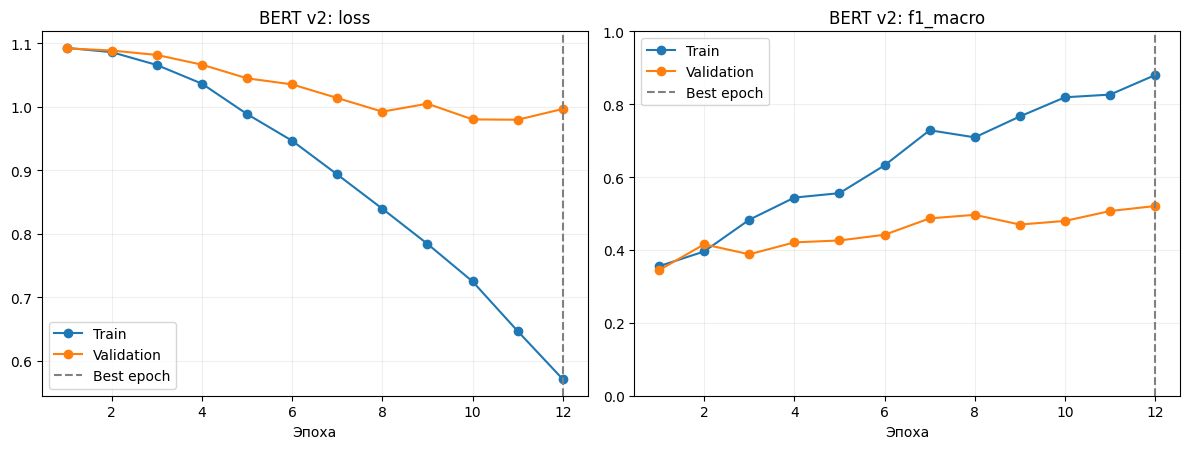

In [111]:
fig, axes=plt.subplots(1,2,figsize=(12,4.6))
for col, metric in enumerate(('loss','f1_macro')):
    axes[col].plot(history_v2_df['epoch'],history_v2_df['train_'+metric],'o-',label='Train')
    axes[col].plot(history_v2_df['epoch'],history_v2_df['validation_'+metric],'o-',label='Validation')
    axes[col].axvline(best_epoch_v2,ls='--',color='gray',label='Best epoch')
    axes[col].set_title(f'BERT v2: {metric}')
    axes[col].set_xlabel('Эпоха'); axes[col].grid(alpha=.2);axes[col].legend()
axes[1].set_ylim(0,1)
fig.tight_layout();fig.savefig(FIG_DIR/'bert_tiny_v2_curves.png',dpi=170,bbox_inches='tight')
plt.show()

#### Test-оценка и сохранение BERT v2

После выбора лучшего checkpoint посчитаем Precision, Recall и F1 по всем трём классам и сохраним матрицу ошибок. Для итоговой таблицы помечаем модель как **исследовательскую** (`exploratory`), потому что первый результат Test уже был известен.

In [112]:
def metrics_v2(true,pred,name):
    prec,rec,f1,_=precision_recall_fscore_support(true,pred,labels=[0,1,2],
                                    average='macro',zero_division=0)
    return {'split':name,'precision_macro':prec,'recall_macro':rec,'f1_macro':f1,
            'f1_weighted':f1_score(true,pred,labels=[0,1,2],average='weighted',zero_division=0),
            'accuracy':accuracy_score(true,pred),'n_samples':len(true)}
rows_v2=[]; test_v2=None
for name, loader in eval_loaders_v2.items():
    stats=epoch_v2(model_v2,loader)
    rows_v2.append(metrics_v2(stats['true'],stats['pred'],name))
    if name=='test':test_v2=stats

,split,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy,n_samples
0,train,0.8625,0.8991,0.8800,0.9474,0.9466,580
1,val,0.5143,0.5276,0.5206,0.8108,0.8069,145
2,test,0.5318,0.5000,0.4842,0.8124,0.8297,182


              precision    recall  f1-score   support

    negative       0.37      0.50      0.42        14
     neutral       0.33      0.07      0.12        14
    positive       0.89      0.93      0.91       154

    accuracy                           0.83       182
   macro avg       0.53      0.50      0.48       182
weighted avg       0.81      0.83      0.81       182



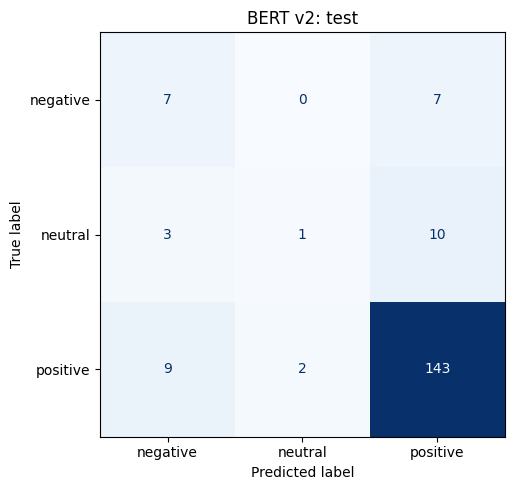

In [113]:
bert_v2_metrics=pd.DataFrame(rows_v2)
bert_v2_metrics.to_csv(RESULTS_DIR/'bert_tiny_v2_metrics.csv',index=False,encoding='utf-8-sig')
display(bert_v2_metrics.round(4))
print(classification_report(test_v2['true'],test_v2['pred'],
      labels=[0,1,2],target_names=LABELS,zero_division=0))
fig, ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(test_v2['true'],test_v2['pred'],labels=[0,1,2],
                       display_labels=LABELS,cmap='Blues',colorbar=False,ax=ax)
ax.set_title('BERT v2: test');fig.tight_layout()
fig.savefig(FIG_DIR/'bert_tiny_v2_confusion.png',dpi=170,bbox_inches='tight');plt.show()
save_dir_v2=MODEL_DIR/'amazon_bert_tiny_balanced_v2'
save_dir_v2.mkdir(exist_ok=True,parents=True)
model_v2.save_pretrained(save_dir_v2);tokenizer_v2.save_pretrained(save_dir_v2)
row_v2=bert_v2_metrics.loc[bert_v2_metrics.split=='test'].iloc[0]

In [114]:
benchmark_v2={'model':'BERT-tiny balanced v2 (exploratory)',
              'representation':'BERT-tiny + linear head, inverse-frequency loss',
              'classes':'1-2 negative, 3 neutral, 4-5 positive',
              'precision_macro':float(row_v2.precision_macro),
              'recall_macro':float(row_v2.recall_macro),
              'f1_macro':float(row_v2.f1_macro),
              'f1_weighted':float(row_v2.f1_weighted),
              'accuracy':float(row_v2.accuracy),
              'training_seconds':float(training_seconds_v2),
              'best_epoch':int(best_epoch_v2),
              'validation_f1_macro':float(best_val_v2),
              'epochs_run':len(history_v2_df),
              'train_n':580,'val_n':145,'test_n':182,'seed':SEED,
              'study_status':'exploratory_after_original_test_seen'}

In [115]:
pd.DataFrame([benchmark_v2]).to_csv(RESULTS_DIR/'benchmark_bert_v2.csv',index=False,encoding='utf-8-sig')
print('Модель:',save_dir_v2)
print('BERT v2 validation Macro F1:',round(best_val_v2,4),'(исходный BERT: 0.3046)')

Модель: models\amazon_bert_tiny_balanced_v2
BERT v2 validation Macro F1: 0.5206 (исходный BERT: 0.3046)


#### Результаты BERT v2

На Test: **Macro Precision = 0,5318**, **Macro Recall = 0,5000**, **Macro F1 = 0,4842**, **Accuracy = 82,97%**. F1 по классам: **0,42** для negative, **0,12** для neutral, **0,91** для positive. Повторный эксперимент помог перестать предсказывать один-единственный класс, но нейтральные отзывы по-прежнему распознаются плохо.

Время обучения v2 — **74,35 с**. Несмотря на улучшение относительно v1, этот результат **исследовательский**, поскольку мы уже видели первоначальные показатели на Test.

### Шаг 7. Классические методы для единого бенчмарка

Для финальной таблицы недостаточно перенести цифры из ЛР №3: там использовались другие обучающие данные (725 отзывов в Train против 580 здесь). Поэтому на **этом же разбиении** заново обучим три классических подхода: **Multinomial Naive Bayes**, **Linear SVM** и **Logistic Regression** с TF-IDF. Добавим DummyClassifier, всегда выбирающий наиболее частый класс.

TF-IDF преобразует текст в разреженный вектор весов слов и биграмм. В отличие от Word2Vec, здесь сохраняется информация о конкретных словах и их локальных сочетаниях. Словарь и IDF вычисляем **только по Train**, гиперпараметры выбираем по Validation.

#### Общий TF-IDF по Train

Создаём один векторизатор слов и биграмм для всех классических моделей. `fit_transform` выполняется только на Train. Для Validation и Test используем `transform`, чтобы не допустить утечки IDF-статистик.

In [116]:
SEED=42
DATA_DIR,RESULTS_DIR,MODEL_DIR=(Path('data'),Path('results'),Path('models'))
RESULTS_DIR.mkdir(exist_ok=True,parents=True)
MODEL_DIR.mkdir(exist_ok=True,parents=True)
splits_cl={k:pd.read_csv(DATA_DIR/f'lab4_{k}.csv') for k in ('train','val','test')}
assert [len(splits_cl[k]) for k in ('train','val','test')]==[580,145,182]
assert not (set(splits_cl['train'].Text) & set(splits_cl['test'].Text))
assert not (set(splits_cl['train'].Text) & set(splits_cl['val'].Text))
assert not (set(splits_cl['val'].Text) & set(splits_cl['test'].Text))
y_train_cl=splits_cl['train'].target.astype(int).to_numpy()

In [117]:
y_val_cl=splits_cl['val'].target.astype(int).to_numpy()
y_test_cl=splits_cl['test'].target.astype(int).to_numpy()
vec_cl=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=20000,
                       sublinear_tf=True,lowercase=True,strip_accents='unicode')
tf0=time.perf_counter()
X_train_cl=vec_cl.fit_transform(splits_cl['train'].Text.astype(str))
X_val_cl=vec_cl.transform(splits_cl['val'].Text.astype(str))
X_test_cl=vec_cl.transform(splits_cl['test'].Text.astype(str))
tfidf_seconds_cl=time.perf_counter()-tf0
print('TF-IDF shapes:',X_train_cl.shape,X_val_cl.shape,X_test_cl.shape)
print(f'Векторизация train/val/test: {tfidf_seconds_cl:.3f} с')
joblib.dump(vec_cl,MODEL_DIR/'amazon_tfidf_vectorizer.joblib')

TF-IDF shapes: (580, 11586) (145, 11586) (182, 11586)
Векторизация train/val/test: 0.230 с


['models\\amazon_tfidf_vectorizer.joblib']

#### Подбор параметров Naive Bayes, SVM и Logistic Regression

Для каждой архитектуры проверим несколько значений `alpha` или `C`, оценим их на Validation Macro F1 и сохраним лучшую конфигурацию. DummyClassifier добавим как минимальный ориентир. Тестовые метки здесь нигде не используются.

In [118]:
configs_cl={
    'Naive Bayes TF-IDF': [(f'alpha={alpha}',MultinomialNB(alpha=alpha))
                          for alpha in (0.1,1.0,5.0)],
    'Linear SVM TF-IDF': [(f'C={c}',LinearSVC(C=c,class_weight='balanced',
                                               random_state=SEED,max_iter=10000))
                         for c in (0.01,0.1,1.0,10.0)],
    'Logistic Regression TF-IDF': [(f'C={c}',LogisticRegression(C=c,
                                 class_weight='balanced',max_iter=3000))
                         for c in (0.01,0.1,1.0,10.0)],
    'Majority class (Dummy)': [('most_frequent',DummyClassifier(strategy='most_frequent'))],
}
selection_cl=[]; best_classical_cl={}

In [119]:
for name,candidates in configs_cl.items():
    best_f1=-1.0; total_fit=0.0
    for config,estimator in candidates:
        t0=time.perf_counter();estimator.fit(X_train_cl,y_train_cl)
        fit_seconds=time.perf_counter()-t0
        total_fit+=fit_seconds
        val_pred=estimator.predict(X_val_cl)
        val_f1=f1_score(y_val_cl,val_pred,average='macro',labels=[0,1,2],zero_division=0)
        selection_cl.append({'model':name,'config':config,'validation_f1_macro':val_f1,
                             'fit_seconds':fit_seconds})
        if val_f1>best_f1+1e-12:
            best_f1=val_f1
            best_classical_cl[name]={
                'model':estimator,'config':config,'validation_f1_macro':val_f1,
                'training_seconds':fit_seconds}
    best_classical_cl[name]['search_seconds']=total_fit
    joblib.dump(best_classical_cl[name]['model'], MODEL_DIR / (
        name.lower().replace(' ','_').replace('(','').replace(')','')+'.joblib'))

In [120]:
selection_cl_df=pd.DataFrame(selection_cl).sort_values(['model','validation_f1_macro'],ascending=[True,False])
selection_cl_df.to_csv(RESULTS_DIR/'classical_selection.csv',index=False,encoding='utf-8-sig')
display(selection_cl_df.round(4))

,model,config,validation_f1_macro,fit_seconds
5,Linear SVM TF-IDF,C=1.0,0.4042,0.0132
6,Linear SVM TF-IDF,C=10.0,0.4042,0.0578
3,Linear SVM TF-IDF,C=0.01,0.3046,0.0067
4,Linear SVM TF-IDF,C=0.1,0.3046,0.0103
8,Logistic Regression TF-IDF,C=0.1,0.4339,0.0370
10,Logistic Regression TF-IDF,C=10.0,0.4042,0.1256
7,Logistic Regression TF-IDF,C=0.01,0.3954,0.0204
9,Logistic Regression TF-IDF,C=1.0,0.3906,0.1278
11,Majority class (Dummy),most_frequent,0.3046,0.0004
0,Naive Bayes TF-IDF,alpha=0.1,0.3046,0.0047


#### Итоговые показатели классических моделей

Оценим модели на Test после завершения выбора конфигураций. Выведем общую таблицу и подробный `classification_report` лучшего классического кандидата по Validation — особенно интересен нейтральный класс.

In [121]:
def metric_row_cl(true,pred):
    p,r,f,_=precision_recall_fscore_support(true,pred,labels=[0,1,2],
                  average='macro',zero_division=0)
    return {'precision_macro':float(p),'recall_macro':float(r),'f1_macro':float(f),
            'f1_weighted':float(f1_score(true,pred,average='weighted',
                                         labels=[0,1,2],zero_division=0)),
            'accuracy':float(accuracy_score(true,pred))}

rows_classical_cl=[]

In [122]:
for name,entry in best_classical_cl.items():
    predictions=entry['model'].predict(X_test_cl)
    row={'model':name,
         'representation':'TF-IDF word 1-2 grams' if name!='Majority class (Dummy)' else 'Most frequent class',
         'classes':'1-2 negative, 3 neutral, 4-5 positive',
         **metric_row_cl(y_test_cl,predictions),
         'training_seconds':entry['training_seconds'],
         'search_seconds':entry['search_seconds'],
         'tfidf_vectorization_seconds':tfidf_seconds_cl,
         'best_config':entry['config'],
         'validation_f1_macro':entry['validation_f1_macro'],
         'train_n':580,'val_n':145,'test_n':182,'seed':SEED}
    rows_classical_cl.append(row)
    print(f'{name}: {entry["config"]}; Val Macro F1={entry["validation_f1_macro"]:.4f}; '
          f'Test Macro F1={row["f1_macro"]:.4f}')

Naive Bayes TF-IDF: alpha=0.1; Val Macro F1=0.3046; Test Macro F1=0.3056
Linear SVM TF-IDF: C=1.0; Val Macro F1=0.4042; Test Macro F1=0.3509
Logistic Regression TF-IDF: C=0.1; Val Macro F1=0.4339; Test Macro F1=0.5523
Majority class (Dummy): most_frequent; Val Macro F1=0.3046; Test Macro F1=0.3056


In [123]:
classical_benchmark=pd.DataFrame(rows_classical_cl)
classical_benchmark.to_csv(RESULTS_DIR/'benchmark_classical.csv',index=False,encoding='utf-8-sig')
display(classical_benchmark[['model','precision_macro','recall_macro','f1_macro',
                             'f1_weighted','accuracy','training_seconds']].round(4))

leading_cl=max(best_classical_cl,key=lambda n: best_classical_cl[n]['validation_f1_macro'])
print('Лучшая классическая модель по validation:',leading_cl)
print(classification_report(y_test_cl,best_classical_cl[leading_cl]['model'].predict(X_test_cl),
                            labels=[0,1,2],target_names=['negative','neutral','positive'],zero_division=0))

,model,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy,training_seconds
0,Naive Bayes TF-IDF,0.2821,0.3333,0.3056,0.7756,0.8462,0.0047
1,Linear SVM TF-IDF,0.6169,0.3571,0.3509,0.7882,0.8516,0.0132
2,Logistic Regression TF-IDF,0.5558,0.5758,0.5523,0.8402,0.8571,0.0370
3,Majority class (Dummy),0.2821,0.3333,0.3056,0.7756,0.8462,0.0004


Лучшая классическая модель по validation: Logistic Regression TF-IDF
              precision    recall  f1-score   support

    negative       0.56      0.71      0.62        14
     neutral       0.20      0.07      0.11        14
    positive       0.91      0.94      0.93       154

    accuracy                           0.86       182
   macro avg       0.56      0.58      0.55       182
weighted avg       0.83      0.86      0.84       182



#### Что показали классические методы

Самый высокий **Test Macro F1 = 0,5523** у **TF-IDF + Logistic Regression**. Linear SVM получил **0,3509**, а Naive Bayes — **0,3056**. Качество отличается даже при одинаковых признаках, поскольку алгоритмы по-разному учатся на редких классах и используют разные предположения о данных.

### Шаг 7 (продолжение). Сводный сравнительный бенчмарк

Соберём метрики **всех моделей, обученных на общем Train/Validation/Test**, в одну таблицу. Для каждого метода приведём Precision, Recall, Macro F1, Weighted F1, Accuracy и время обучения, а затем отсортируем результаты по основной метрике.

Время следует интерпретировать аккуратно. Для одних моделей измерялось обучение классификатора на готовых признаках, для других — эпохи нейросети с валидацией. Обучение Word2Vec и расчёт TF-IDF учитывались отдельно.

#### Объединяем результаты всех экспериментов

Считываем сохранённые CSV предыдущих этапов, присоединяем классические модели и исследовательскую BERT v2. Проверяем, что все результаты соответствуют общим размерам Train/Validation/Test; таблицу сортируем по Test Macro F1.

In [124]:
RESULTS_DIR=Path('results')
previous=RESULTS_DIR/'benchmark_steps2_6.csv'
classic=RESULTS_DIR/'benchmark_classical.csv'
if not previous.is_file():
    raise FileNotFoundError(f'{previous} не найден. Сначала запустите ячейку 30 с исходным BERT.')
if not classic.is_file():
    raise FileNotFoundError(f'{classic} не найден. Сначала выполните шаг 38.')

In [125]:
parts=[pd.read_csv(previous),pd.read_csv(classic)]
v2_path=RESULTS_DIR/'benchmark_bert_v2.csv'
if v2_path.is_file():
    parts.append(pd.read_csv(v2_path))
else:
    print('BERT v2 ещё не запущен: таблица без дополнительного эксперимента.')
benchmark_final=pd.concat(parts,ignore_index=True)
benchmark_final=benchmark_final.drop_duplicates(subset=['model'],keep='last')
for metric in ('precision_macro','recall_macro','f1_macro','f1_weighted','accuracy'):
    benchmark_final[metric]=pd.to_numeric(benchmark_final[metric],errors='raise')
assert (benchmark_final['test_n']==182).all(), 'В таблице есть другой тестовый набор!'
assert (benchmark_final['train_n']==580).all(), 'В таблице есть другое число train-отзывов!'

In [126]:
assert (benchmark_final['val_n']==145).all(), 'В таблице есть другое число validation-отзывов!'
benchmark_final=benchmark_final.sort_values('f1_macro',ascending=False).reset_index(drop=True)
benchmark_final['fit_or_training_seconds']=pd.to_numeric(benchmark_final.get('training_seconds'),errors='coerce')
if 'logreg_fit_seconds' in benchmark_final:
    miss=benchmark_final['fit_or_training_seconds'].isna()
    benchmark_final.loc[miss,'fit_or_training_seconds']=pd.to_numeric(
        benchmark_final.loc[miss,'logreg_fit_seconds'],errors='coerce')
show_cols=['model','representation','precision_macro','recall_macro','f1_macro',
           'f1_weighted','accuracy','fit_or_training_seconds']
display(benchmark_final[show_cols].round(4))
benchmark_final.to_csv(RESULTS_DIR/'benchmark_final_all_models.csv',index=False,encoding='utf-8-sig')

,model,representation,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy,fit_or_training_seconds
0,Logistic Regression TF-IDF,TF-IDF word 1-2 grams,0.5558,0.5758,0.5523,0.8402,0.8571,0.0370
1,Mean Word2Vec + Logistic Regression,Word2Vec Skip-gram 100d / mean pooling,0.4701,0.5649,0.4858,0.7675,0.7198,0.0302
2,BERT-tiny balanced v2 (exploratory),"BERT-tiny + linear head, inverse-frequency loss",0.5318,0.5000,0.4842,0.8124,0.8297,74.3462
3,Linear SVM TF-IDF,TF-IDF word 1-2 grams,0.6169,0.3571,0.3509,0.7882,0.8516,0.0132
4,BiLSTM Dynamic,Random trainable embeddings 100d + BiLSTM,0.3322,0.3398,0.3312,0.7676,0.8077,58.8968
5,BiLSTM Static,Word2Vec 100d frozen + BiLSTM,0.2821,0.3333,0.3056,0.7756,0.8462,24.4469
6,BERT-tiny Fine-Tuning,"prajjwal1/bert-tiny, WordPiece, pretrained BER...",0.2821,0.3333,0.3056,0.7756,0.8462,31.7284
7,Naive Bayes TF-IDF,TF-IDF word 1-2 grams,0.2821,0.3333,0.3056,0.7756,0.8462,0.0047
8,Majority class (Dummy),Most frequent class,0.2821,0.3333,0.3056,0.7756,0.8462,0.0004


In [127]:
benchmark_final[show_cols].round(4).to_csv(RESULTS_DIR/'benchmark_final_short.csv',index=False,encoding='utf-8-sig')
print('Результат:',RESULTS_DIR/'benchmark_final_all_models.csv')
print('Важно: времена обучения разных архитектур не включают одинаковые операции; '
      'Word2Vec-векторизация учитывается отдельно, а для классики указан best-fit без подбора.')

Результат: results\benchmark_final_all_models.csv
Важно: времена обучения разных архитектур не включают одинаковые операции; Word2Vec-векторизация учитывается отдельно, а для классики указан best-fit без подбора.


#### Итоги

Лидер по **Test Macro F1 — TF-IDF + Logistic Regression (0,5523)**; дальше идут Mean Word2Vec + Logistic Regression (**0,4858**) и BERT-tiny v2 (**0,4842**). При этом TF-IDF + Logistic Regression не решает проблему нейтральных отзывов: F1 этого класса — всего **0,11**.

Разница между результатами получена на одной небольшой тестовой выборке. Это наблюдаемый рейтинг, но не статистическое доказательство преимущества архитектуры во всех условиях.

#### Наглядное сравнение Macro F1

Горизонтальная диаграмма позволяет увидеть, насколько различается качество моделей по основному критерию.

In [128]:
def show_final_benchmark():
    ordered = benchmark_final.sort_values('f1_macro', ascending=True)
    fig, ax = plt.subplots(figsize=(11, max(5, 0.55 * len(ordered))))
    ax.barh(ordered.model, ordered.f1_macro, color='#5478A7')
    for i, value in enumerate(ordered.f1_macro):
        ax.text(value + .005, i, f'{value:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, max(0.7, ordered.f1_macro.max() + .11))
    ax.set_xlabel('Macro F1 на одинаковом тестовом наборе (182 отзыва)')
    ax.set_title('Лабораторная №4: качество моделей')
    ax.grid(axis='x', alpha=.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'final_benchmark_macro_f1.png', dpi=170, bbox_inches='tight')
    plt.show()
    print('Для времени обучения см. CSV: fit_or_training_seconds.')

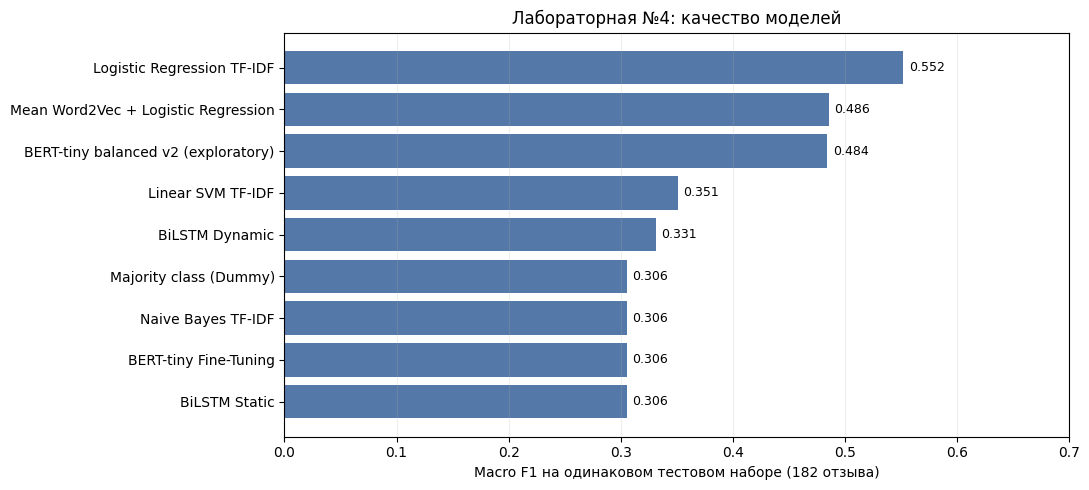

Для времени обучения см. CSV: fit_or_training_seconds.


In [129]:
show_final_benchmark()

#### Сопоставление затрат

В сводной таблице `fit_or_training_seconds` показывает время обучения выбранного классификатора. Для нейросетей в него входят валидационные проходы. Для классических моделей подготовка признаков и подбор параметров учитываются отдельно.

### Шаг 8. Итоговые выводы

На тестовой выборке из 182 отзывов лучший результат показала **логистическая регрессия с TF-IDF**. Её Macro F1 составил **0,5523**, Accuracy — **85,71%**. Для сравнения, предсказание самого частого класса даёт почти такую же Accuracy (84,62%), но только 0,3056 по Macro F1. Разница особенно важна для нейтральных отзывов: даже у лучшей модели F1 этого класса составил всего 0,11.

Усреднение векторов собственной Word2Vec и логистическая регрессия дали **Macro F1 = 0,4858**. Близость слов `battery` и `life` показывает, что эмбеддинги уловили характерную для отзывов лексику. При усреднении теряется порядок слов, тогда как TF-IDF с биграммами сохраняет часть локальных сочетаний.

**BiLSTM Static** с замороженными эмбеддингами получила 0,3056 по Macro F1, **BiLSTM Dynamic** с обучаемыми эмбеддингами — 0,3312. У Dynamic показатель на train к последней эпохе достиг 1,0, а на validation — лишь 0,5400. Такой разрыв согласуется с переобучением на 580 обучающих отзывах.

Исходная **BERT-tiny** предсказывала положительный класс для всех тестовых отзывов и получила Macro F1 = 0,3056. В дополнительном эксперименте с усиленными весами редких классов и большим числом эпох результат вырос до 0,4842. Эту конфигурацию выбрали после просмотра тестовых результатов первой версии. Для независимой проверки улучшения нужна новая выборка.

По замерам сохранённого запуска обучение логистической регрессии на готовых TF-IDF-признаках заняло **0,0370 с**, построение признаков для трёх выборок — **0,230 с**. Обучение Word2Vec заняло **16,51 с**, получение векторов документов — **7,43 с**, обучение регрессии на них — **0,0302 с**. BiLSTM Static и Dynamic обучались **24,45 и 58,90 с**, BERT v1 и v2 — **31,73 и 74,35 с** соответственно. Замеры охватывают разные этапы, поэтому точное отношение времени полных конвейеров по ним вычислить нельзя.

На этом разбиении TF-IDF с логистической регрессией дал наибольший Macro F1 при небольших вычислительных затратах. Возможные причины — малый обучающий корпус и преобладание положительных оценок. В тесте всего по 14 отрицательных и нейтральных отзывов, поэтому порядок моделей по одному запуску нужно интерпретировать осторожно.